# Q2B | Display the Statistical Values

> B. Display the statistical values for each of the attributes, along with visualizations (e.g., histogram) of the distributions for each attribute. Explain noticeable traits for key attributes. Are there any attributes that might require special treatment? If so, what special treatment might they require?

**IMPORTANT**
This dataset has no train / test split of its own, so the split is made at the top of this notebook. It is chronological: the earliest days are train and the latest days are test. Every statistic below is computed on the training rows only, so no analysis or treatment decision is influenced by the test data (data snooping).

# Answer Summary

**Statistics and visualizations** (train rows only: 584 rows, 2011-01-01 to 2012-08-06)
- Each continuous attribute (`Temp`, `FeelsLike`, `Humidity`, `Wind`) has a statistics table (center, spread, skew, kurtosis, IQR outliers, correlation with `Rentals`) and five plots: histogram, QQ plot, box plot, a scatter against `Rentals` (linear, LOWESS and the best candidate shapes), and a chart of every candidate shape's R² gain over the linear fit. The target has the table, histogram and QQ plot.
- Each categorical attribute (`Year`, `Season`, `Month`, `Weekday`, `IsWorkday`, `IsHoliday`, `Weather`) has a table of `Rentals` statistics per level, a bar chart of rows per level, a `Rentals` box plot per level with the level means R², a chart of every candidate encoding's adjusted R² gain over the code as a number (attributes with more than 2 levels), and a table of interactions with each continuous attribute. `Season` and `Month` are shown again split by `Year`, with `Year` in every candidate fit.
- `Casual`, `Registered`, `ID` and `Date` get none (see Columns Left Out): `Casual` and `Registered` are parts of the target, `ID` is the row number, and `Date` is flat by construction.

**Noticeable traits**
- Target: roughly symmetric, with more than one peak, no missing values and no IQR outliers.
- Strength of the relationship with `Rentals`: moderate for `FeelsLike`, `Temp`, `Month`, `Season` and `Year`. Weak for `Weather`, `Wind` and `Humidity`. None for `Weekday`, `IsWorkday` and `IsHoliday` (level means R² 0.00).
- Shape: `Temp` and `FeelsLike` rise and then go flat past a corner, so the cap and the hinge beat LOWESS (+0.05), while the gradual re-expressions fall short of it.
- `Humidity` is flat, then falls steeply at the humid end: shapes from all three families that isolate the drop gain +0.04 to +0.05, while the straight line explains almost nothing.
- `Wind` is weak and close to straight: no shape gains more than +0.02.
- `Year` behind `Season` and `Month`: `Year` 1 runs higher than `Year` 0 in every season and month that has both, and much of the plain `Season` and `Month` gain is really `Year` (`Month`'s best gain falls from +0.41 to +0.27 once `Year` is in the fit).
- Calendar shape with `Year` in the fit: `Month` is two straight runs, up to month 6 and down after it, so a hinge at month 6 matches one-hot with 2 columns against 11.
- `Season` 4 sits level with season 2 once `Year` is in the fit, so 3 groups ({1} | {2, 4} | {3}) match one-hot with 2 columns against 3.
- Calendar coverage: `Season` 4 and months 9 to 12 are `Year` 0 only in train. Most of the test dates (2012-08-07 to 2012-12-31) fall in that stretch of the calendar.
- Interactions: `Month` changes how `Temp`, `FeelsLike` and `Humidity` move `Rentals` (one slope per month gains +0.04 to +0.06). No other interaction reaches the 0.03 tier.
- Rare levels: `IsHoliday` 1 and `Weather` 3 (16 and 18 rows). `Weather` 3 is also the level furthest from the overall mean.
- `Weather` as a number predicts level 3 too high, but that level is rare, so the code as a number is within 0.01 of one-hot.
- Outliers: the 12 high `Wind` outliers sit on the trend. Only the single low `Humidity` outlier sits off it.

**Special treatment**
- Feature engineering: recommend a cap on `Temp` and on `FeelsLike`, and the hinge or the floor on `Humidity` (+0.05 each). Also recommended: quantile bins on `Temp`, `FeelsLike` and `Humidity`, and a very humid day flag (step) on `Humidity`. Worth testing, small gain: a windy day flag (step) on `Wind`. On `FeelsLike`, prefer the cap over the hinge, which turns down where `Rentals` are flat. Avoid a warm day flag (step) on `Temp` and `FeelsLike` (it loses R²), and the hinge, floor, cap and quantile bins on `Wind`. On `Month`, recommend the hinge at month 6; on `Season`, 3 groups ({1} | {2, 4} | {3}). Avoid the other group merges on both, and every merge on `Weather`.
- Transformations: recommend Yeo-Johnson on `Humidity` (+0.05), then its reflected reciprocal and reflected log, and on `Temp` Yeo-Johnson or the reciprocal as a second choice behind the cap. Worth testing, small gain: log and sqrt on `Temp`, and all four re-expressions on `FeelsLike`. Avoid every re-expression on `Wind`, the reflected sqrt on `Humidity`, and winsorize on all four continuous attributes.
- Encoding: keep `Weather` as a number: one-hot falls in the avoid tier over it. If the `Season` and `Month` picks above are not used, one-hot (one 0 / 1 column per level, with one level left out as the baseline: 3 columns for `Season`, 11 for `Month`), or sine / cosine with 2 waves on `Month` (tied). Avoid `Season` and `Month` as numbers, and sine / cosine with 1 wave on both.
- Interactions: recommend `Month` by `FeelsLike`, `Temp` or `Humidity`, one slope per month (+0.04 to +0.06). Worth testing, small gain: `Season` by `Humidity`. Avoid `Year` by `Season` or `Month` (most test-period levels have no `Year` 1 rows) and every other interaction.
- Outliers: keep the high `Wind` outliers: they follow the trend. With a hinge on `Humidity`, clip its single low outlier up to the lower IQR fence (0.172); the floor, the step and the re-expressions already treat it like any other dry day.
- Dropping: drop `Casual` and `Registered` (they add up to `Rentals`, so they leak the target) and `ID` (the row number). Avoid `Date` as a raw number: every test day is later than every train day, so its slope would be carried past the training range. Drop `Weekday`, `IsWorkday` and `IsHoliday`: no encoding or interaction of them gains more than +0.01. Test the model without `Wind`.
- None: `Rentals`: no transform (log or square root), as it is already roughly symmetric (skew 0.067).

---

# Imports

In [1]:
import pandas as pd

import Q2.consts as Q2_CONSTS
from consts import TEST_SIZE

from utils import (
	read_csv_to_df,
	SPLIT,
	STATISTICS,
	PLOTTING,
)

pd.set_option('display.max_rows', None)
pd.set_option('display.min_rows', None)
pd.set_option('display.max_columns', None)

# Fetch Data

In [2]:
df = read_csv_to_df(path=Q2_CONSTS.DATA_PATH, parse_dates=["dteday"])
df = df.rename(columns=Q2_CONSTS.SHORT_NAMES)

# Train / Test Split

In [3]:
train_df, test_df = SPLIT.chronological_split(df=df, date_col="Date", test_size=TEST_SIZE)

pd.DataFrame({
	"rows": [len(train_df), len(test_df)],
	"% of rows": [round(len(train_df) / len(df) * 100, 2), round(len(test_df) / len(df) * 100, 2)],
	"first date": [f"{train_df['Date'].min():%Y-%m-%d}", f"{test_df['Date'].min():%Y-%m-%d}"],
	"last date": [f"{train_df['Date'].max():%Y-%m-%d}", f"{test_df['Date'].max():%Y-%m-%d}"],
}, index=["train", "test"])

,rows,% of rows,first date,last date
train,584,79.89,2011-01-01,2012-08-06
test,147,20.11,2012-08-07,2012-12-31


## Columns Left Out

`Casual`, `Registered`, `ID` and `Date` get no statistics or plots below:
- `Casual` and `Registered`: the two parts of `Rentals` (Q2A: they add up to it on every row). Neither is known until the day is over, so neither can be an attribute.
- `ID`: the row number, neither continuous nor categorical (Q2A).
- `Date`: one row per day with no gaps (Q2A), so its distribution is flat by construction. Its calendar parts are described through `Year`, `Season`, `Month` and `Weekday`.

# Statistical Values: Continuous Attributes

## How to Read the Plots

- **Statistics table:** the skew RoT row reads a skew between -0.5 and 0.5 as roughly symmetric, 0.5 to 1 either way as moderately skewed, and beyond 1 as highly skewed. The notes call an attribute skewed when it is moderately or highly skewed. The kurtosis RoT row reads an excess kurtosis below -1 as light tails (platykurtic), -1 to 1 as near-normal tails (mesokurtic), 1 to 7 as heavy tails (leptokurtic) and above 7 as very heavy tails.
- **Strength labels** (in the notes): graded on the straight line's R² in the scatter legend for a continuous attribute, and the level means R² in the box plot title for a categorical one. Under 0.01 is none, 0.01 to 0.16 weak, 0.16 to 0.49 moderate, 0.49 or more strong: the squares of the |r| cutoffs 0.1, 0.4 and 0.7 from Schober, Boer and Schwarte (2018), as Ferguson (2009) does.
- **Histogram w/ normal overlay:** the attribute's distribution against a normal curve with the same mean and SD. The orange and green lines mark the mean and the median, and the gray lines mark 1, 2 and 3 SDs from the mean. Gaps between the bars and the red curve show skew, values piling up at one end, or more than one peak.
- **QQ plot:** the sorted values against the values a normal distribution would produce. Points on the red line mean normal.
  - Low end below the line and high end above it: heavy tails. The reverse: light tails.
  - Points bowing above the line through the middle: left skew. Bowing below: right skew.
  - A flat run at one end: values piling up against a limit.
- **Box plot:** the box spans the middle half of the values (Q1 to Q3), with the median as the green line and the mean as the orange diamond. The whiskers reach the furthest values inside the IQR fences, and the dots past them are the IQR outliers counted in the statistics table. A mean far from the median points to skew.
- **Scatter plot + candidate shapes:**
  - **Scatter plot** (R² in the legend):
    - Linear: the straight line on the raw attribute, the only shape the raw attribute gives a linear regression. Its R² is the bar every candidate shape has to beat.
    - LOWESS: a smoothed local trend with no fixed shape. Where it bends away from the linear fit, the raw attribute misfits. It hints at the shape to aim for, and its R² hints at how much a better shape could gain.
    - Candidate shapes: the best shape of each family, drawn in the family's color only when it beats the linear R² by 0.01 or more.
  - **Candidate shapes chart**: each bar is a shape's R² gain over the linear fit (red line at 0), highest R² on top. The dashed green line marks LOWESS. The label gives the shape's R², its gain, and how many columns it uses (more columns always fit a little better). The x axis is scaled to each chart's own gains, so a gain of 0.01 can draw as a long bar: compare the numbers, not the bar lengths.
  - **How every candidate is fitted**: each shape rebuilds the attribute as one or more new columns, then fits an ordinary linear regression of `Rentals` on those columns. Only the attribute is changed, never `Rentals`. Each is graded by its R² on the train rows.
  - **How a setting is searched**: a shape with a setting (a threshold, shift, power or clip point) is fitted once for every value in a fixed list, and the value with the highest R² is kept. The search sees the same rows it is scored on, so those R² values are optimistic. A gain of 0.01 to 0.02 over the linear R² is not evidence on its own.
  - **Tiers** (R² gain over the linear fit, rounded to 2 decimals): 0.03 or more, recommend; 0.02, worth testing, small gain; 0.01 or less, avoid.

**Re-expression family**: replace the attribute with one new column, a bent version of it. The fit is a straight line on the new scale, which draws as a smooth curve on the original one. It targets a LOWESS curve that bends gradually and in the same direction across the whole range.

| Shape | Goal | What it does to the attribute | Setting and how it is set |
| --- | --- | --- | --- |
| log | Follow a curve that is steep at one end and flattens toward the other, with the steep end at either the low or the high end. | As it is, `log(x + shift)` spreads the low values apart and squeezes the high values together, for a curve that is steep at the low end. Reflected, `log(shift - x)` does the mirror image, for a curve that is steep at the high end. | Direction (as it is or reflected) and shift, searched together. For each direction, the shifts put the value at the steep end (the smallest value, or the largest when reflected) 0.001, 0.003, 0.01, 0.03, 0.1, 0.3, 1, 3 or 10 times the attribute's range above 0. The closer to 0, the harder the bend; the furthest is close to a straight line. As it is, no shift at all is also tried when every value is above 0. Best R² kept. |
| sqrt | The same as log, with a milder bend. | `sqrt(x + shift)`, or reflected `sqrt(shift - x)`: like log, with less stretching at the steep end. | Direction and shift: the same lists as log, plus the steep end placed exactly at 0. |
| reciprocal | The same as log, with the sharpest bend of the three. | `1 / (x + shift)`, or reflected `1 / (shift - x)`: like log, with more stretching at the steep end. It also reverses the order of the values, which the fitted slope reverses back. | Direction and shift: the same lists as log. |
| Yeo-Johnson | Follow a gradual bend in either direction. | A power transform with power λ: λ = 1 leaves the attribute as it is, λ below 1 squeezes the high values (like log), and λ above 1 squeezes the low values, for a curve that is flat at the low end and steep at the high end. It works on 0 and negative values without a shift. | λ: -10 to 30 in steps of 0.5. Best R² kept. |

Log, sqrt and reciprocal are Box-Cox at the powers 0, 0.5 and -1. A straight line fits Box-Cox exactly as well as the plain transform, so Box-Cox is not repeated as its own shape.

Yeo-Johnson has no reflected version: flipping the sign of the attribute gives exactly the fit of Yeo-Johnson at the power 2 - λ, so its powers above 1 already cover the mirror image.

**Piecewise linear family**: straight segments joined at a threshold `t`, so the line can change slope or go flat at one point. It targets a LOWESS curve with a corner, or one that goes flat past some value.

| Shape | Goal | What it does to the attribute | Setting and how it is set |
| --- | --- | --- | --- |
| hinge | Let the slope change at `t`. | Keeps the attribute and adds a second column `max(0, x - t)`, how far the value is past `t` (0 below it). The fit gets one slope below `t` and another above it, joined at `t`. 2 columns. | `t`: every distinct value of the attribute that leaves at least 5% of the rows on each side. Best R² kept. |
| cap | The attribute stops mattering above `t`. | `min(x, t)`: every value above `t` becomes `t`, so the line is flat past it. | `t`: the same search as the hinge. |
| floor | The attribute only starts mattering above `t`. | `max(x, t)`: every value below `t` becomes `t`, so the line is flat before it. | `t`: the same search as the hinge. |
| winsorize | Stop the most extreme values on both ends from pulling the line. | Every value below the p-th percentile becomes the p-th percentile, and every value above the (100 - p)-th becomes the (100 - p)-th. The line is flat past both clip points. | p: 1% to 45% in steps of 1 (45% leaves only the middle 10% as it is). Best R² kept. |

**Bins family**: replace the attribute with groups, and predict each group with its own `Rentals` mean, a staircase. It targets a `Rentals` that jumps between levels instead of changing smoothly.

| Shape | Goal | What it does to the attribute | Setting and how it is set |
| --- | --- | --- | --- |
| step | One `Rentals` level below `t` and another at or above it. | A single 0 / 1 column: 1 when the value is at or above `t`, 0 below it. | `t`: the same search as the hinge. |
| quantile bins | Several levels across the range. | Cuts the attribute into 5 groups with the same number of rows each, one 0 / 1 column per group. One group is the baseline the intercept covers, so 4 columns. | Not searched: 5 bins is fixed, because more bins always fit the train rows a little better, so a search would always pick the most bins tried. |

## Rentals (TARGET)

In [4]:
STATISTICS.continuous_statistics_df(series=train_df[Q2_CONSTS.TARGET])

,Rentals
count,584
missing,0
% missing,0.0
mean,4153.6
std,1788.9
min,431.0
50%,4200.0
max,8362.0
range,7931.0
skew,0.067


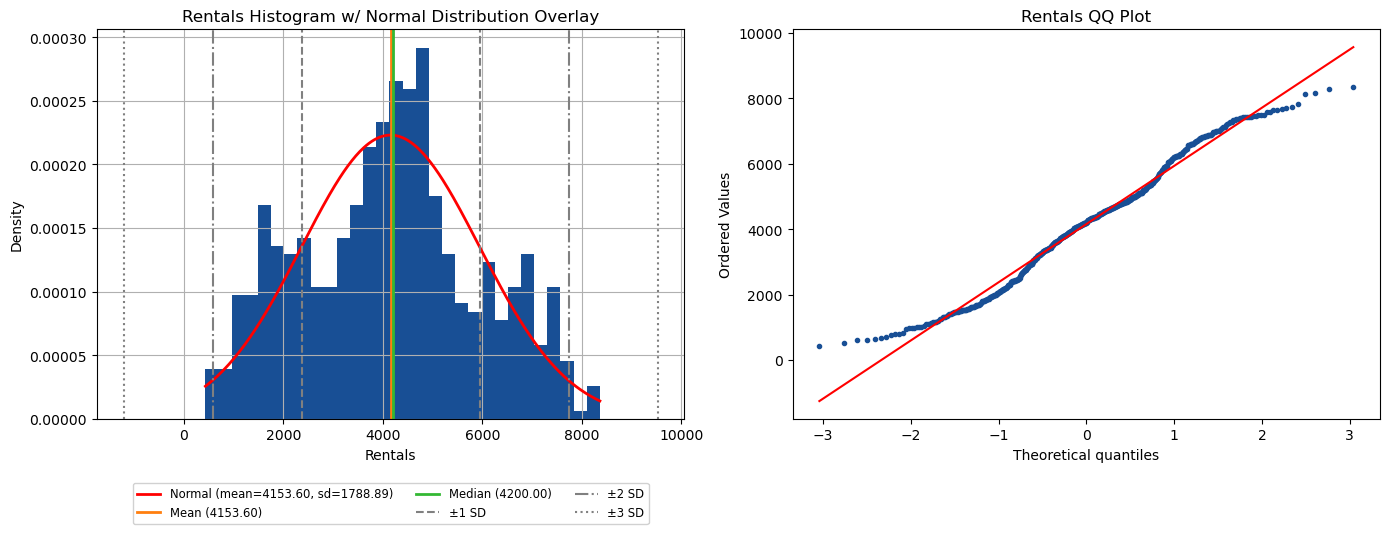

In [5]:
PLOTTING.continuous_distribution_plots(series=train_df[Q2_CONSTS.TARGET]);

### Notes / Observations

#### Noticeable Traits / Key Attributes

- More than one peak: groups of days sit at different `Rentals` levels, so no straight line on a single attribute can reproduce them. The attributes together have to explain those groups.
- No missing values and no IQR outliers: every train row has a usable label, and no single extreme day pulls the fitted line.

#### Special Treatment

- None: no transform (log or square root): `Rentals` is already roughly symmetric (skew 0.067), so either would only skew it and force every prediction to be converted back.

## Temperature

In [6]:
STATISTICS.continuous_statistics_df(series=train_df['Temp'], target=train_df[Q2_CONSTS.TARGET])

,Temp
count,584
missing,0
% missing,0.0
mean,0.497
std,0.188
min,0.059
50%,0.502
max,0.862
range,0.803
skew,-0.083


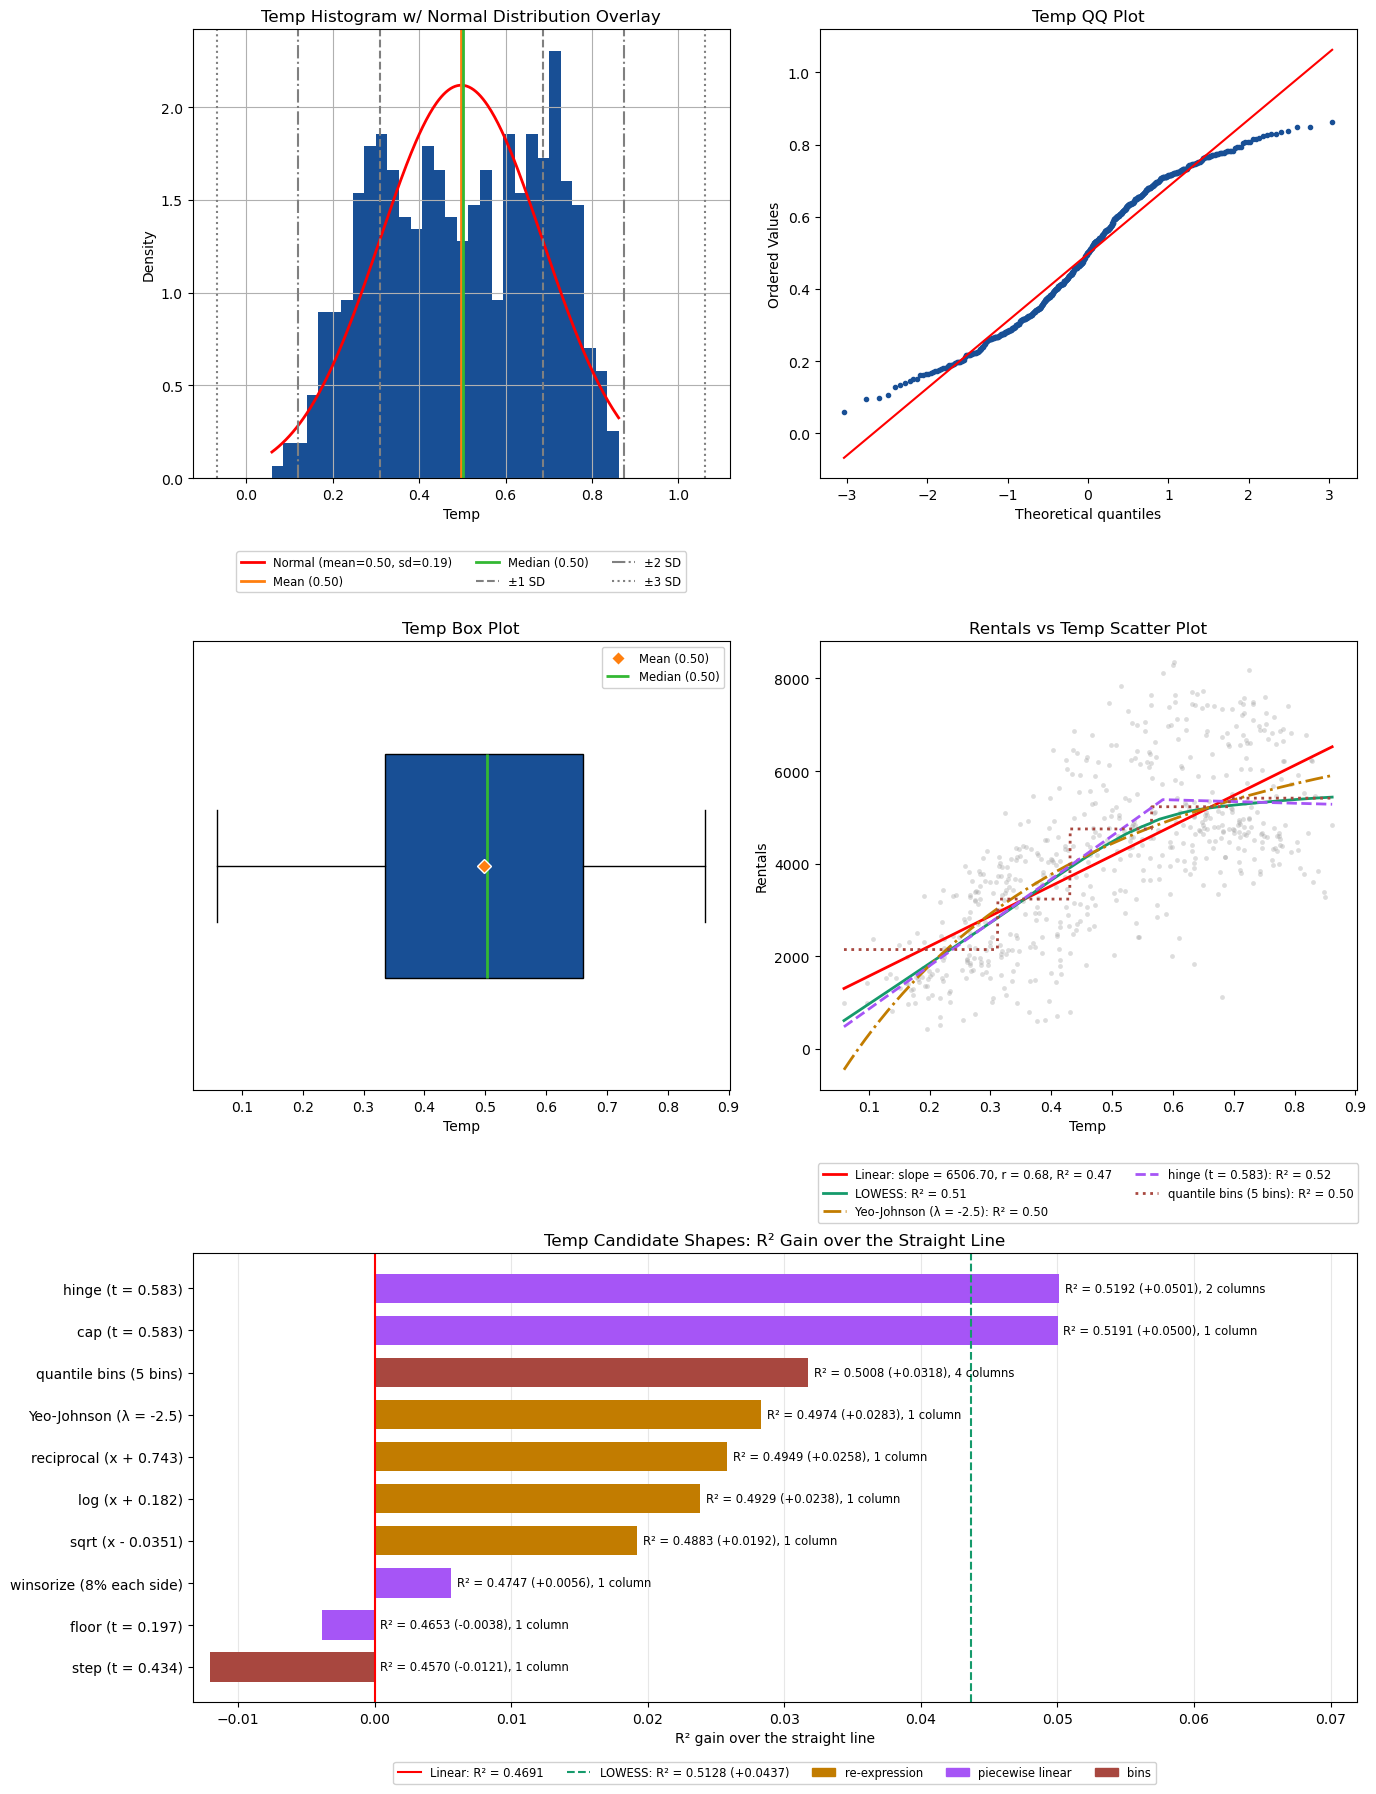

In [7]:
PLOTTING.continuous_single_feature_plots(df=train_df, feature='Temp', target=Q2_CONSTS.TARGET);

### Notes / Observations

#### Noticeable Traits / Key Attributes

- Steep, then flat: `Rentals` climb with `Temp` up to a corner and are flat above it. The straight line over-predicts the coldest and the warmest days and under-predicts the days in between, which costs R² 0.47 against 0.51 for LOWESS.
- The bend is a corner, not a gradual curve: the piecewise shapes that go flat past the corner beat even LOWESS (+0.05), while every re-expression keeps bending past the corner and stays under LOWESS.
- The best re-expression, Yeo-Johnson, misfits both ends: it drops below 0 rentals at the coldest end of the scatter and keeps rising past the corner, so it would predict impossible values on the coldest days and too many rentals on the warmest ones.

#### Special Treatment

- **Feature engineering:** recommend a cap at t = 0.583 (`min(Temp, 0.583)`, +0.05). The hinge at the same t gains the same with two columns instead of one, because it is already flat above t. Quantile bins also reach the 0.03 tier, but as a four column staircase behind the cap. Avoid a warm day flag (step) and the floor: both go flat over a range where `Rentals` climb, and neither gains R².
- **Transformations:** recommend Yeo-Johnson or the reciprocal only as a second choice behind the cap (+0.03 each): the whole family bends gradually where the data has a corner. Log and sqrt are worth testing, small gain. Avoid winsorize: it goes flat at both ends, and only the warm end is flat.

## FeelsLike

In [8]:
STATISTICS.continuous_statistics_df(series=train_df['FeelsLike'], target=train_df[Q2_CONSTS.TARGET])

,FeelsLike
count,584
missing,0
% missing,0.0
mean,0.476
std,0.168
min,0.079
50%,0.49
max,0.841
range,0.762
skew,-0.156


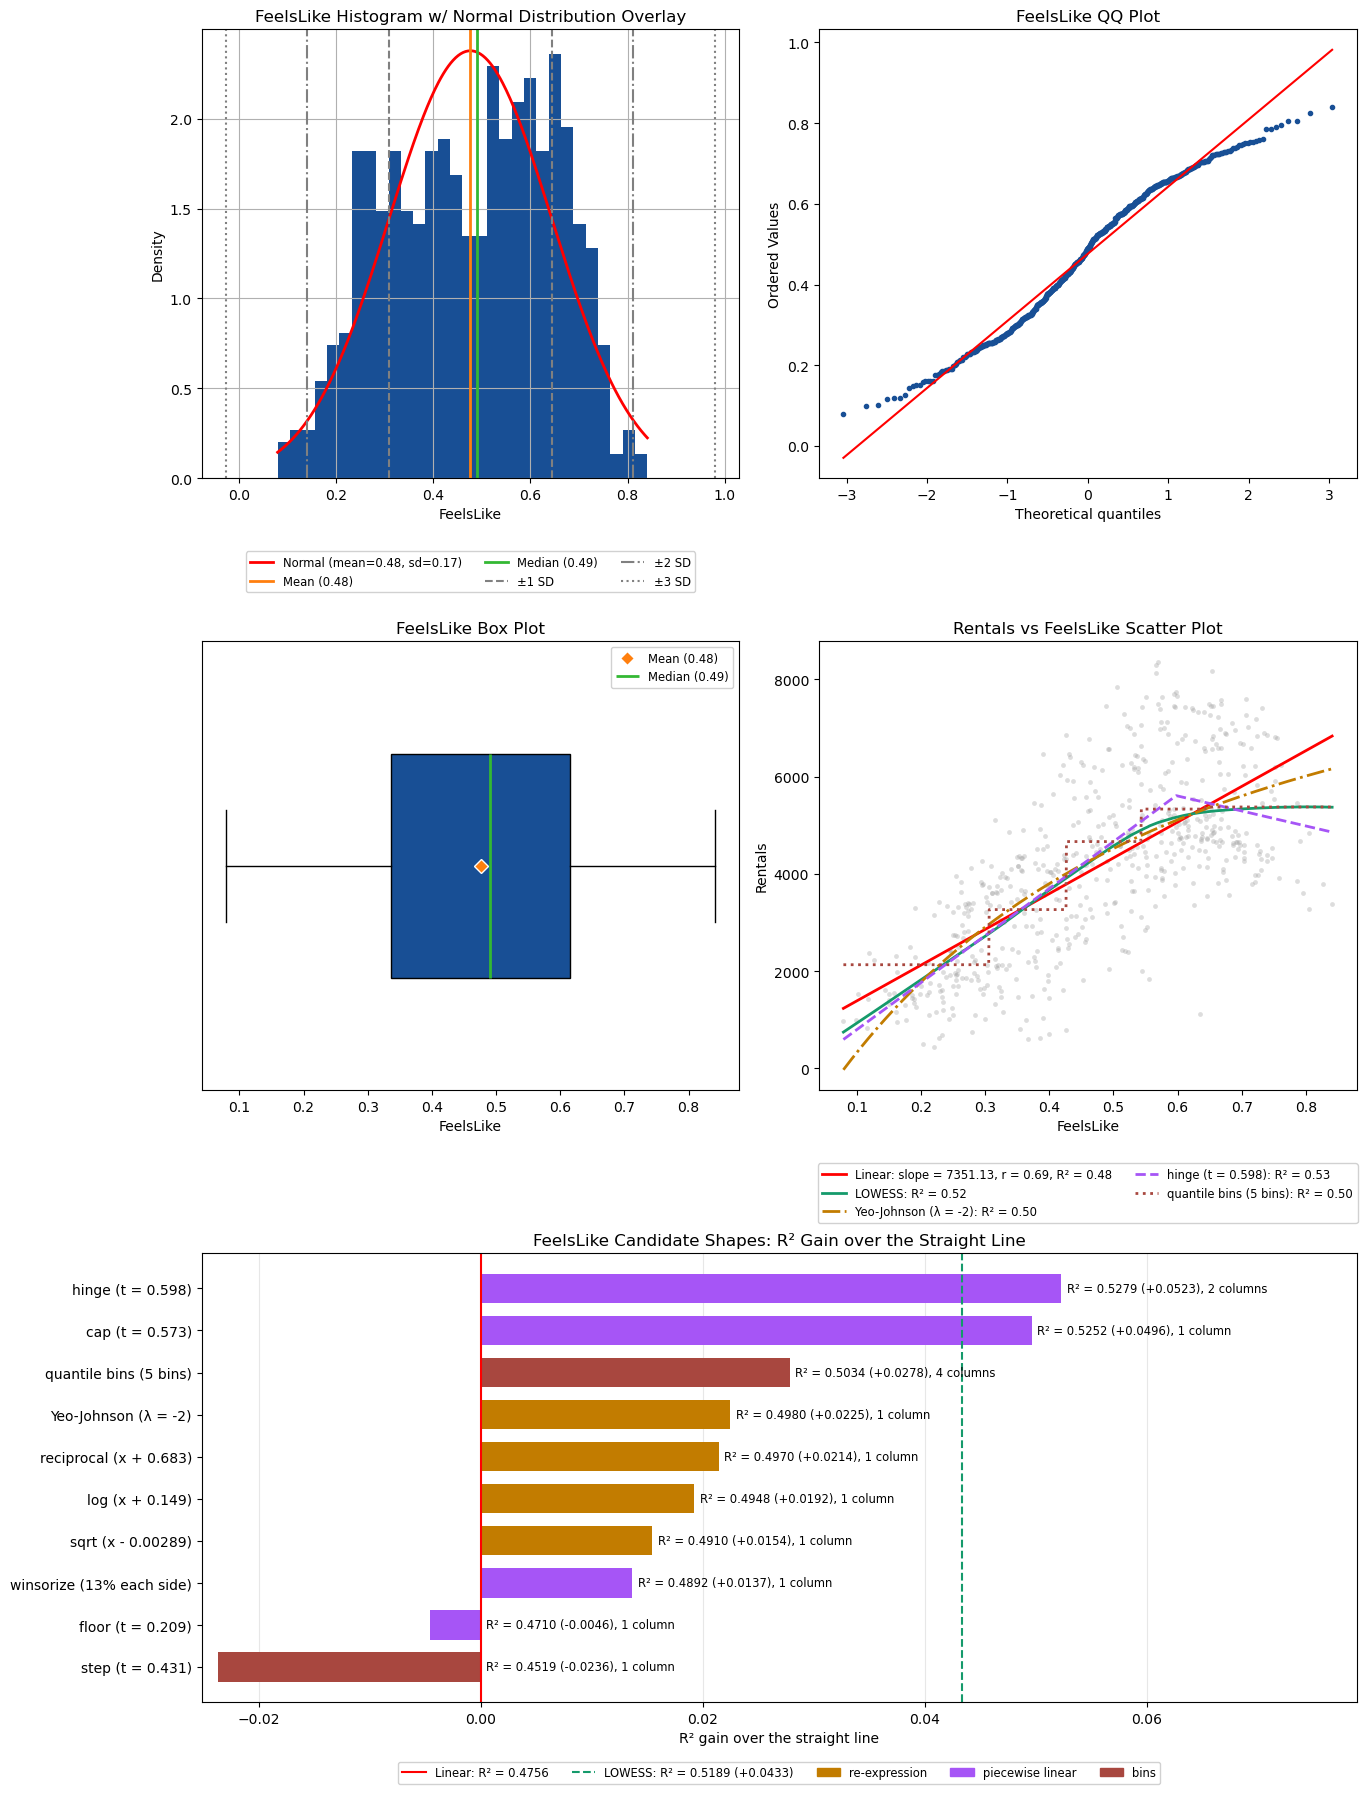

In [9]:
PLOTTING.continuous_single_feature_plots(df=train_df, feature='FeelsLike', target=Q2_CONSTS.TARGET);

### Notes / Observations

#### Noticeable Traits / Key Attributes

- Steep, then flat: `Rentals` climb with `FeelsLike` up to a corner and are flat above it. The straight line over-predicts the coldest and the warmest days, which costs R² 0.48 against 0.52 for LOWESS.
- The cap follows the flat top, the hinge does not: the hinge turns down above its threshold while LOWESS stays flat, so it would predict fewer rentals on the warmest days than the data shows. The cap cannot turn down and gains the same (+0.05 each).
- Gradual bends fall short of the corner: every re-expression gains +0.02, under LOWESS (+0.04), and the best one, Yeo-Johnson, drops toward 0 rentals at the coldest end of the scatter.

#### Special Treatment

- **Feature engineering:** recommend a cap at t = 0.573 (`min(FeelsLike, 0.573)`, +0.05) over the hinge, which turns down above its threshold where LOWESS is flat. Quantile bins also reach the 0.03 tier, but as a four column staircase behind the cap. Avoid a warm day flag (step) and the floor: both go flat over a range where `Rentals` climb, and neither gains R².
- **Transformations:** Yeo-Johnson, the reciprocal, log and sqrt are each worth testing, small gain (+0.02), well behind the cap. Avoid winsorize, which gains less.

## Humidity

In [10]:
STATISTICS.continuous_statistics_df(series=train_df['Humidity'], target=train_df[Q2_CONSTS.TARGET])

,Humidity
count,584
missing,0
% missing,0.0
mean,0.623
std,0.148
min,0.0
50%,0.622
max,0.972
range,0.972
skew,-0.071


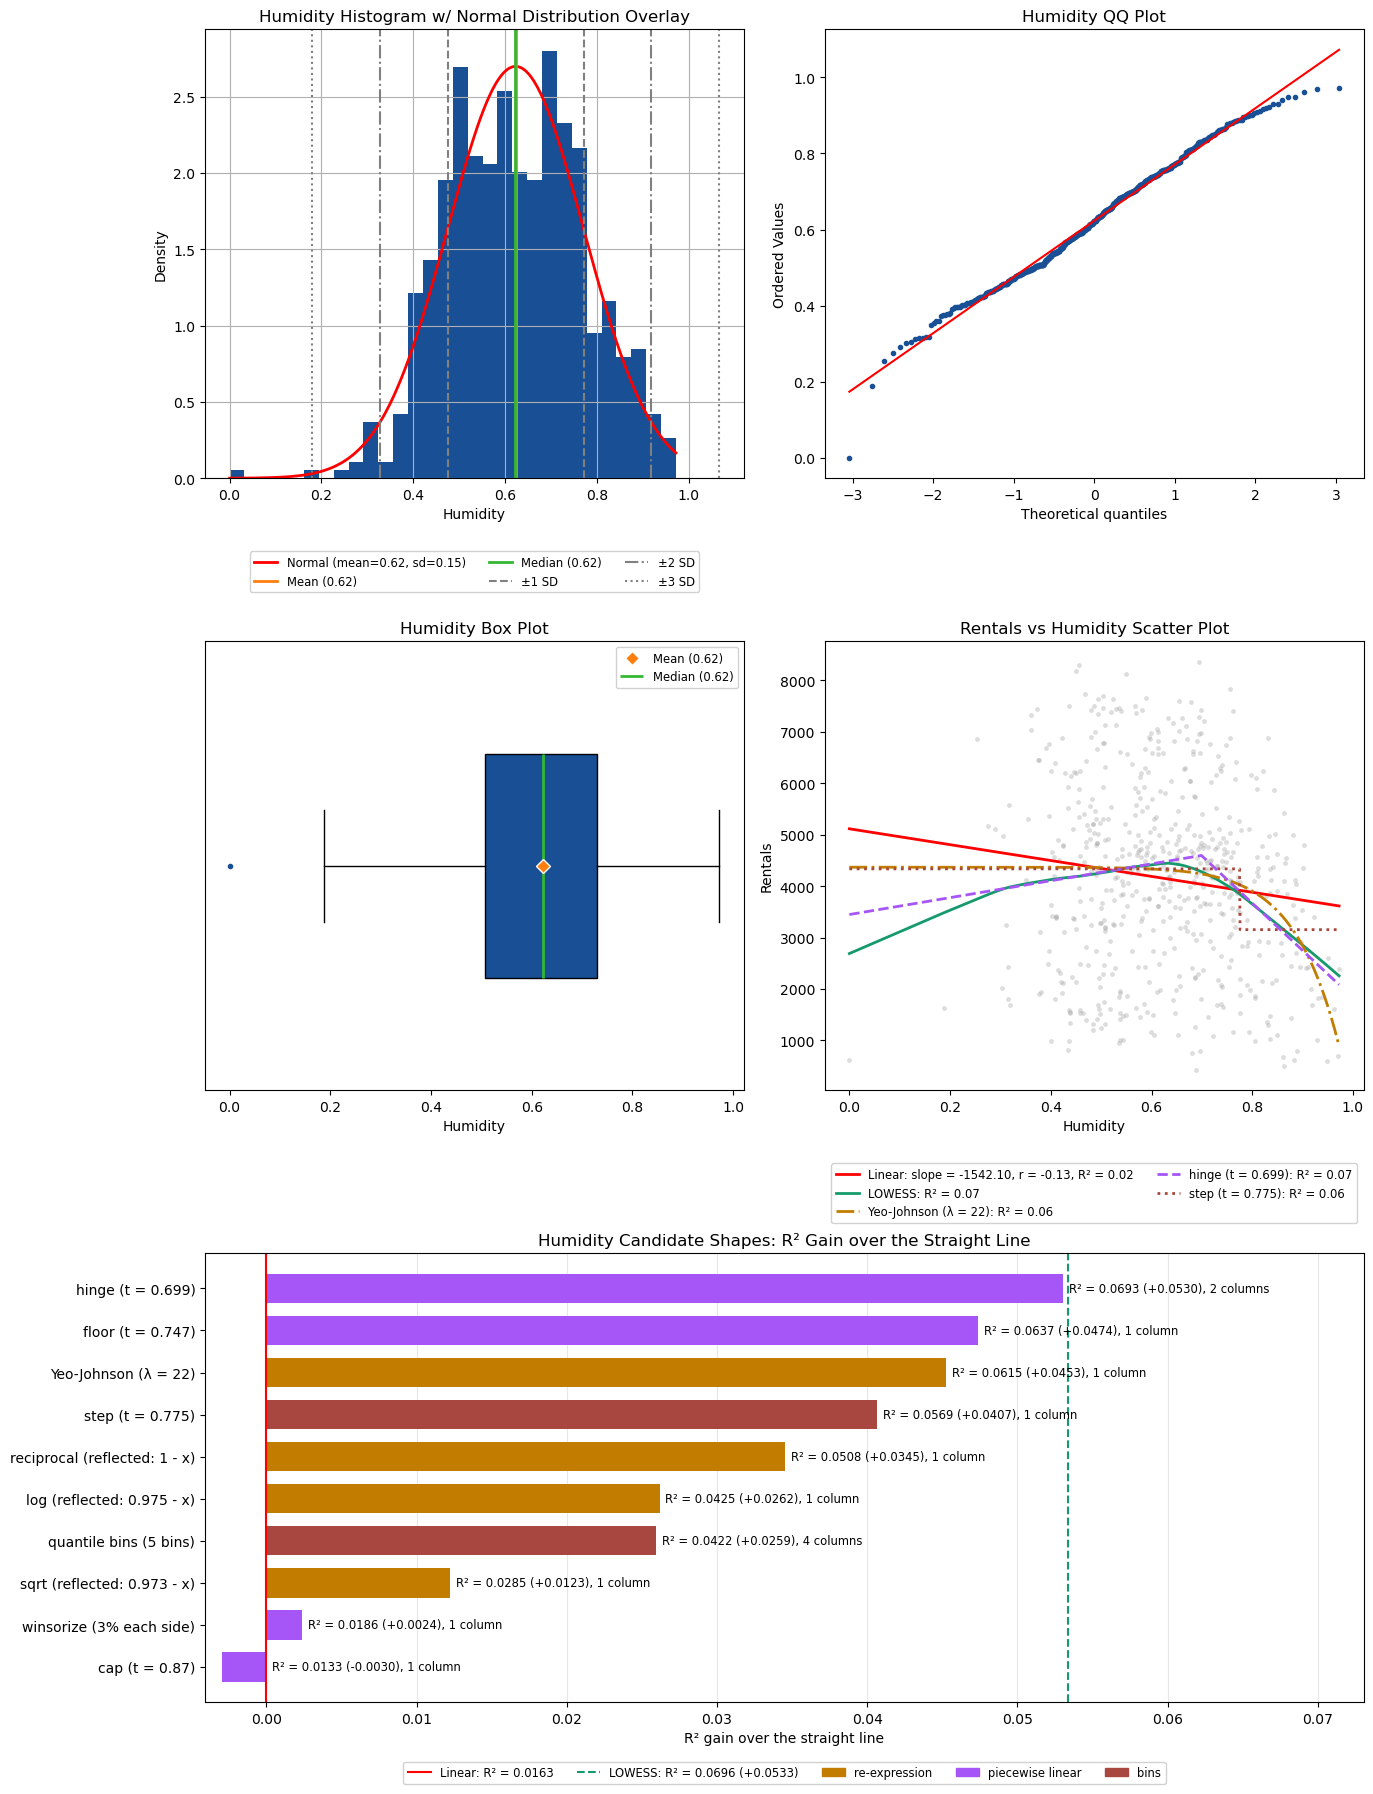

In [11]:
PLOTTING.continuous_single_feature_plots(df=train_df, feature='Humidity', target=Q2_CONSTS.TARGET);

### Notes / Observations

#### Noticeable Traits / Key Attributes

- Flat, then falling: `Rentals` barely change with `Humidity` until the humid end, then fall steeply. The straight line spreads that drop over the whole range, so it over-predicts the most humid days, under-predicts the days just before the drop, and explains almost nothing (R² 0.02).
- The signal is all in the drop: shapes from all three families that isolate it do about equally well (hinge, floor, Yeo-Johnson and step gain +0.04 to +0.05, as much as LOWESS), so where the drop starts matters more than the family.
- Yeo-Johnson at λ = 22 falls well below LOWESS at the highest values, so it would under-predict the most humid days.
- One isolated row at 0.0 (the only IQR outlier) sits far left of every other row, with low `Rentals`. LOWESS bends down toward it at the left edge, a bend that rests on that single row.

#### Special Treatment

- **Feature engineering:** recommend the hinge at t = 0.699 or the floor (`max(Humidity, t)`: no effect below t, a straight fall above it), +0.05 each. A very humid day flag (step) also reaches the 0.03 tier, but it is flat above its threshold where LOWESS keeps falling. Quantile bins reach it too, behind the hinge and the floor: with equal rows per bin, most of their cuts fall in the flat range. Avoid the cap: it flattens the drop and gains nothing.
- **Transformations:** recommend Yeo-Johnson at λ = 22 (+0.05), then the reflected reciprocal and the reflected log: each is flat at the low end and steep at the high end, the shape of the drop. Check Yeo-Johnson's predictions on the most humid days, where it falls below LOWESS. Avoid the reflected sqrt and winsorize: both fall in the avoid tier.
- **Outliers:** with the hinge, clip the single low outlier up to the lower IQR fence (0.172): it is off the trend and is the one point that sets the left end of the line. The floor, the step and the re-expressions are flat at the dry end, so they already give it the prediction of any other dry day.

## Wind

In [12]:
STATISTICS.continuous_statistics_df(series=train_df['Wind'], target=train_df[Q2_CONSTS.TARGET])

,Wind
count,584
missing,0
% missing,0.0
mean,0.194
std,0.076
min,0.022
50%,0.186
max,0.507
range,0.485
skew,0.668


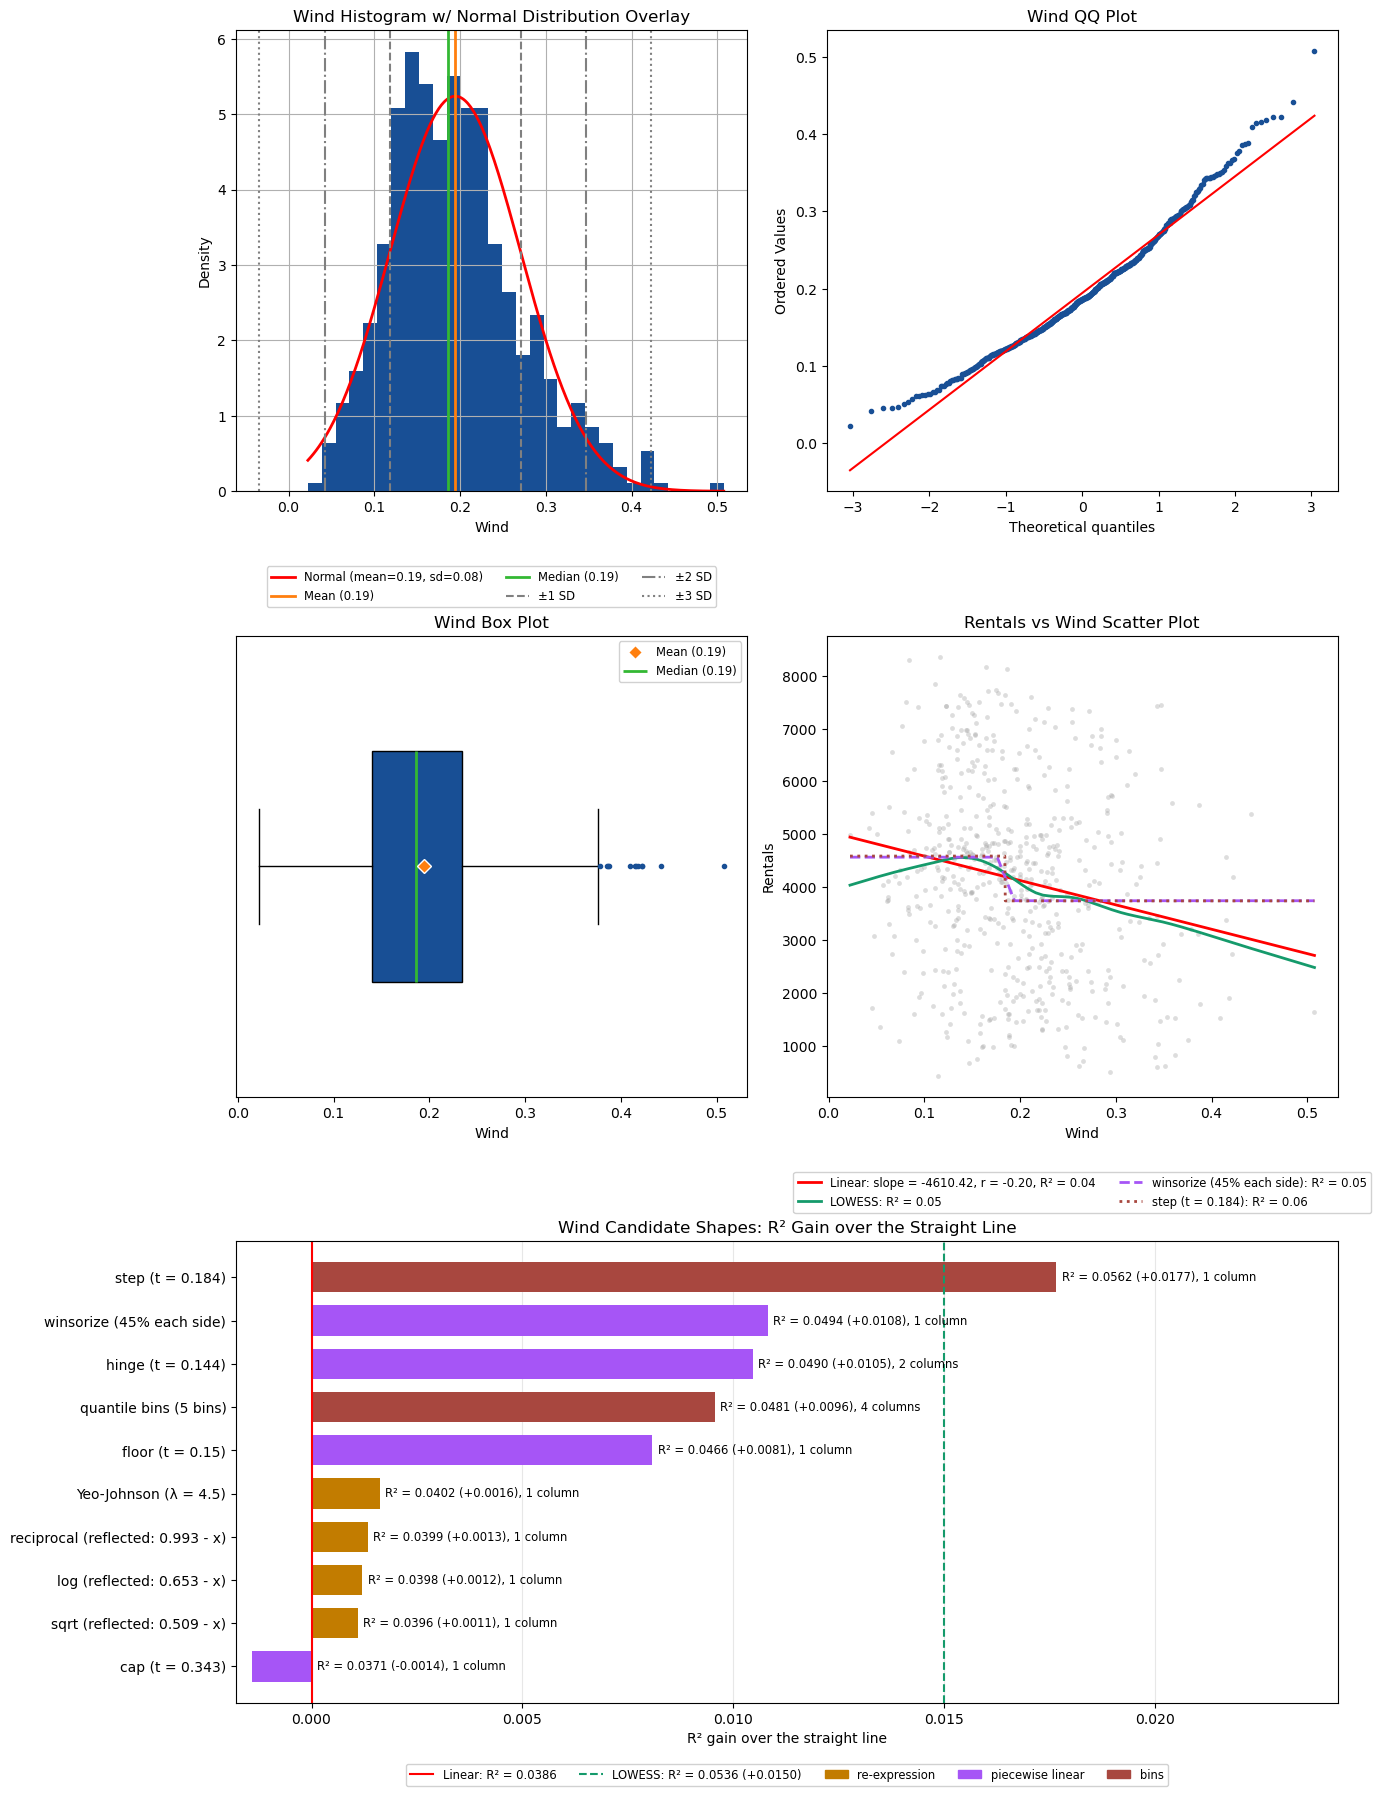

In [13]:
PLOTTING.continuous_single_feature_plots(df=train_df, feature='Wind', target=Q2_CONSTS.TARGET);

### Notes / Observations

#### Noticeable Traits / Key Attributes

- Weak and close to a straight line: linear R² 0.04, and even LOWESS beats it by under 0.02, so no shape of `Wind` can move the predictions much.
- The right skew does not bend the relationship with `Rentals`: every re-expression gains +0.00.
- The 12 high IQR outliers are on the trend: LOWESS keeps falling through them, so they carry the windiest days' lower `Rentals`, not noise.
- Only the step reaches the 0.02 tier (above LOWESS), but it is flat above its threshold while LOWESS keeps falling, so it would over-predict the windiest days.

#### Special Treatment

- **Dropping:** test the model without it: its best shape reaches only R² 0.06.
- **Feature engineering:** if kept, a windy day flag (step at t = 0.184, +0.02) is worth testing, small gain. Avoid the hinge, the floor and quantile bins, which gain less.
- **Transformations:** avoid the whole re-expression family and winsorize: none gains more than +0.01.
- **Outliers:** keep the 12 high outliers, do not clip or drop them: they sit on the falling part of LOWESS, and the cap that flattens them gains nothing.

# Statistical Values: Categorical Attributes

## How to Read the Table and Plots

Applies to every categorical attribute below. Levels are shown as the stored codes.

- **Table:** `Rentals` statistics within each level, the level's share of the rows, and its mean minus the overall mean (4,154).
- **Count plot:** the number of train rows at each level. A thin level gets a coefficient set by few days.
- **Box plot:** `Rentals` at each level, drawn as in the continuous box plot.
  - **Level means R²** (title): the share of the variation in `Rentals` explained by predicting every row with the mean of its level. It is the R² of one-hot, the most any encoding of this one attribute can reach.
  - **Marks:** a flat line in the family's color across each level box, at the `Rentals` the best candidate of that family predicts for the level. Drawn only when that candidate beats the straight line by 0.01 or more in adjusted R².
- **Candidate encodings chart** (attributes with more than 2 levels only: with 2 levels every encoding is the same single 0 / 1 column):
  - Each bar is a candidate's adjusted R² gain over the straight line, the code used as a number with one slope (red line at 0). The dashed line marks one-hot, the ceiling. The text beside each bar gives its adjusted R², its gain and its number of columns. The x axis is scaled to each chart's own gains: compare the numbers, not the bar lengths.
  - **How every candidate is fitted**: each candidate rebuilds the attribute as one or more new columns, then fits an ordinary linear regression of `Rentals` on those columns, on the train rows.
  - **Adjusted R²**: R² minus a charge for every column, so a column of pure noise earns 0 on average. These candidates use 1 to 11 columns, and on 584 rows pure noise alone is worth about 0.02 of R² for Month's 11 one-hot columns, a full tier. The continuous shapes use at most 4 columns, so plain R² is used there.
  - **Tiers** (adjusted gain over the straight line, rounded to 2 decimals): 0.03 or more, recommend; 0.02, worth testing; 0.01 or less, avoid. Candidates within 0.01 of the best are treated as equal, and the one with fewer columns is preferred. A candidate more than 0.01 behind the best is avoided, even when its own gain is in the recommend tier.
  - **How a setting is searched**: cuts and thresholds are searched on the same rows they are scored on, so every gain is a little optimistic. Adjusted R² charges for columns, not for the settings tried.
  - A candidate that would use as many columns as one-hot gives the same fit, so it is not shown.

| Family | Candidate | What it does to the attribute | Columns |
| --- | --- | --- | --- |
| groups | one-hot | One 0 / 1 column per level, with one level left out as the baseline. | levels minus 1 |
| groups | 2 groups | Sorts the levels by mean `Rentals` and cuts them into 2 groups where the fit is best. | 1 |
| groups | 3 groups | The same, with 2 cuts. | 2 |
| piecewise linear | hinge | Keeps the code and adds `max(0, code - t)`, so the slope changes at `t`. | 2 |
| piecewise linear | cap | `min(code, t)`: flat above `t`. | 1 |
| piecewise linear | floor | `max(code, t)`: flat below `t`. | 1 |
| cyclic | 1 wave | Sine and cosine of the code, 1 wave per cycle. | 2 |
| cyclic | 2 waves | Sine and cosine with 1 and 2 waves per cycle. | 4 |

The threshold `t` is searched over the level codes. The cyclic family is tried on `Season`, `Month` and `Weekday` only, whose last code sits next to the first (December to January, Saturday to Sunday, season 4 to season 1).

Left out on purpose: a step on the code (every step is one of the 2-group cuts), re-expressions such as log (no meaning on a code), contrast codings (same R² as one-hot), target and frequency encoding (they leak the target, and the counts reflect where the train dates stop), and splines (as in the continuous screen).

- **Year Context** (`Season` and `Month`): the same table and charts with every level split by `Year`. Its level means R² uses one mean per level and `Year` pair. In its candidate chart every fit also includes `Year` as a fixed extra column, so a gain is what the attribute adds beyond what `Year` already explains, and each mark predicts its box with that box's `Year`. Its box labels are short: `1 Y0` is level 1 at `Year` 0, and `n` is the box's row count.
- **Interactions with continuous attributes table**: the one place besides Year Context where attributes are crossed, on purpose. It checks whether the attribute changes how a continuous attribute moves `Rentals` (a different slope per level). One row per continuous attribute:
  - `adjusted r2 without`: the attribute's one-hot columns plus the raw continuous attribute.
  - `adjusted r2 with`: the same, plus one slope of the continuous attribute per level.
  - `gain`: read with the same tiers. `columns added`: levels minus 1.
  - `Year` by `Season` or `Month` is not tested: in train, season 4 and months 9 to 12 have no `Year` 1 rows, and that stretch is most of the test period.

## Year

In [14]:
STATISTICS.categorical_statistics_df(df=train_df, feature='Year', target=Q2_CONSTS.TARGET)

,count,% of rows,mean,std,min,25%,50%,75%,max,mean - overall mean
Year,,,,,,,,,,
0,365,62.5,3405.762,1378.754,431.0,2132.0,3740.0,4586.0,6043.0,-747.838
1,219,37.5,5399.995,1699.125,1027.0,4108.0,5823.0,6805.0,8362.0,1246.396


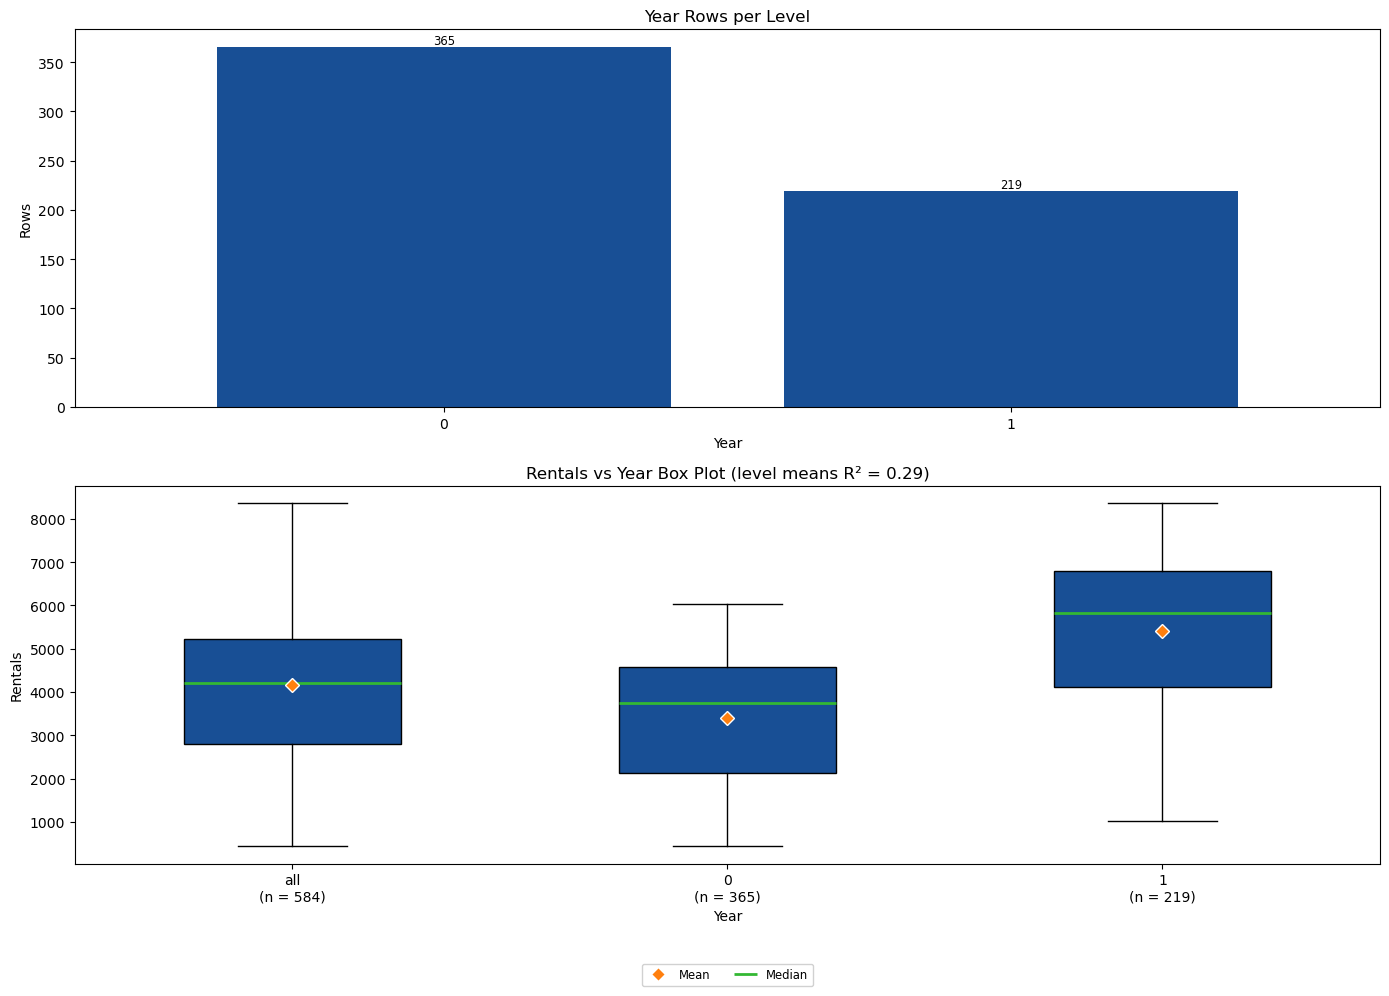

In [15]:
PLOTTING.categorical_single_feature_plots(df=train_df, feature='Year', target=Q2_CONSTS.TARGET);

### Interactions with Continuous Attributes

This table crosses `Year` with each continuous attribute on purpose, to check whether `Year` changes how that attribute moves `Rentals`. `Year` by `Season` or `Month` is not tested: season 4 and months 9 to 12 have no `Year` 1 rows in train.

In [16]:
STATISTICS.interaction_r2_df(df=train_df, feature='Year', target=Q2_CONSTS.TARGET, continuous=Q2_CONSTS.CONTINUOUS)

,adjusted r2 without,adjusted r2 with,gain,columns added
continuous attribute,,,,
Temp,0.7097,0.7152,0.0055,1
FeelsLike,0.7158,0.7215,0.0057,1
Humidity,0.2903,0.2911,0.0008,1
Wind,0.3393,0.3384,-0.0009,1


### Notes / Observations

#### Noticeable Traits / Key Attributes

- Moderate on its own: `Year` 1 days average far more rentals, so the `Year` column shifts every prediction by a large amount (level means R² 0.29).
- The test shift is learned from part of the year: every test day is `Year` 1, but train holds only the first 219 days of `Year` 1, so the shift added to every test prediction comes from months 1 to 8 only.

#### Special Treatment

- **Dropping:** keep it in every model: in the Year Context tables, `Year` 1 is higher at every `Season` level and in every month that has both years.
- **Interactions:** avoid `Year` by any continuous attribute (largest gain +0.01, `FeelsLike`) and `Year` by `Season` or `Month`: most of their test-period cells (season 4, months 9 to 12) have no `Year` 1 train rows.

## Season (with Year Context)

In [17]:
STATISTICS.categorical_statistics_df(df=train_df, feature='Season', target=Q2_CONSTS.TARGET)

,count,% of rows,mean,std,min,25%,50%,75%,max,mean - overall mean
Season,,,,,,,,,,
1,170,29.110,2651.412,1412.458,431.0,1544.75,2296.0,3570.25,7836.0,-1502.188
2,184,31.507,4992.332,1695.977,795.0,4003.00,4941.5,6377.00,8362.0,838.732
3,141,24.144,5178.979,1294.236,1115.0,4390.00,4840.0,6043.00,8173.0,1025.379
4,89,15.240,3664.461,983.006,627.0,3068.00,3717.0,4205.00,5511.0,-489.139


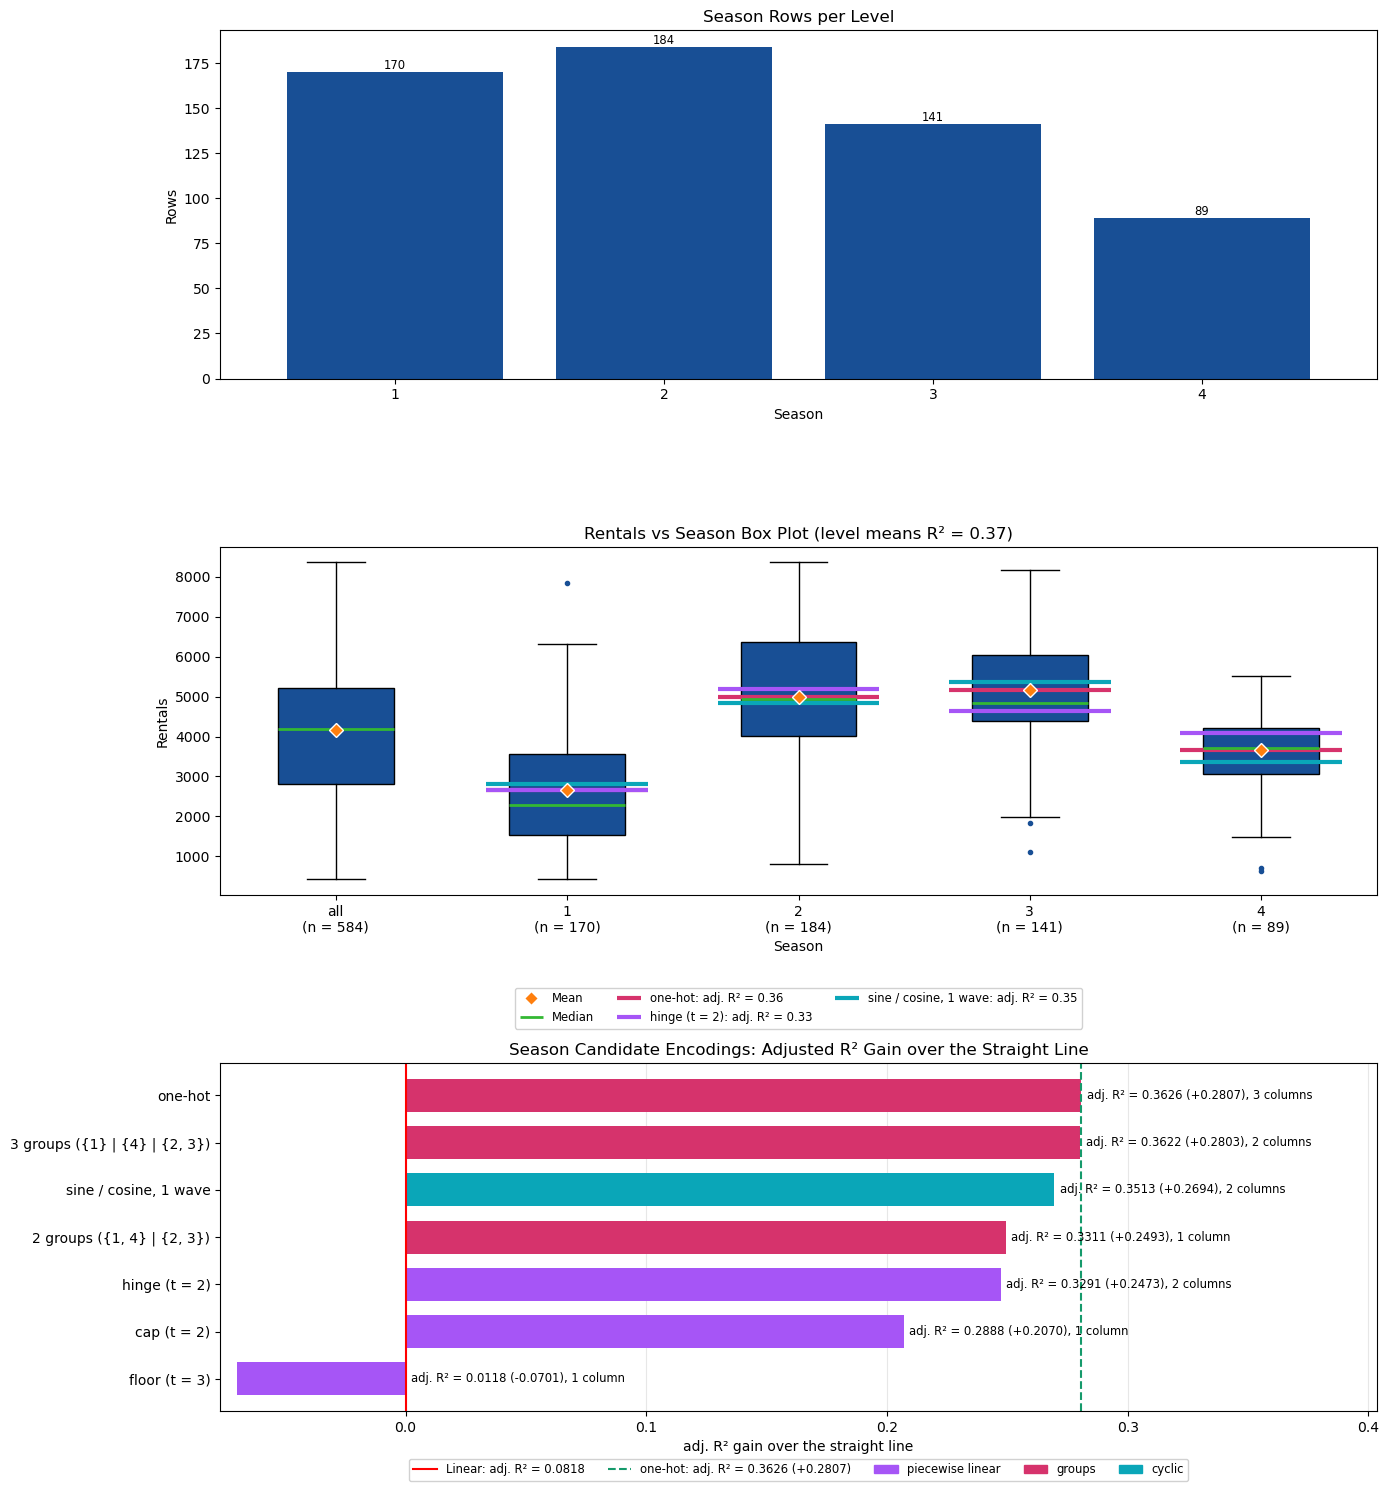

In [18]:
PLOTTING.categorical_single_feature_plots(df=train_df, feature='Season', target=Q2_CONSTS.TARGET, period=4);

### Year Context

Train holds 365 rows at `Year` 0 and 219 at `Year` 1, so the levels are not spread evenly over the two years. The chronological split leaves `Season` 4 with `Year` 0 rows only in train (the rows per level chart below), and most of the test days (2012-08-07 to 2012-12-31, the split table) fall in that stretch of the calendar. So the single attribute view above mixes the two years: season 4 holds first-year days alone, while the other seasons hold both. That is why this section crosses `Season` with `Year`, a stated exception to looking at one attribute at a time. The table and plots below split every level by `Year`.

In [19]:
STATISTICS.categorical_statistics_df(df=train_df, feature='Season', by='Year', target=Q2_CONSTS.TARGET)

count  % of rows      mean       std     min      25%     50%  \
Season Year                                                                  
1      0        90     15.411  1666.667   614.013   431.0  1251.75  1602.5   
       1        80     13.699  3759.250  1222.923  1301.0  2944.00  3769.0   
2      0        92     15.753  3775.174  1138.901   795.0  3060.00  4085.5   
       1        92     15.753  6209.489  1221.346  1027.0  5621.00  6384.0   
3      0        94     16.096  4464.362   798.348  1115.0  4179.25  4615.5   
       1        47      8.048  6608.213   823.844  4459.0  6119.00  6824.0   
4      0        89     15.240  3664.461   983.006   627.0  3068.00  3717.0   

                 75%     max  mean - overall mean  
Season Year                                        
1      0     2030.75  3239.0            -2486.933  
       1     4366.00  7836.0             -394.349  
2      0     4664.25  5805.0             -378.425  
       1     6998.75  8362.0             2055.890  
3      0     4877.25  6043.0              310.762  
       1     7238.50  8173.0             2454.613  
4      0     4205.00  5511.0             -489.139

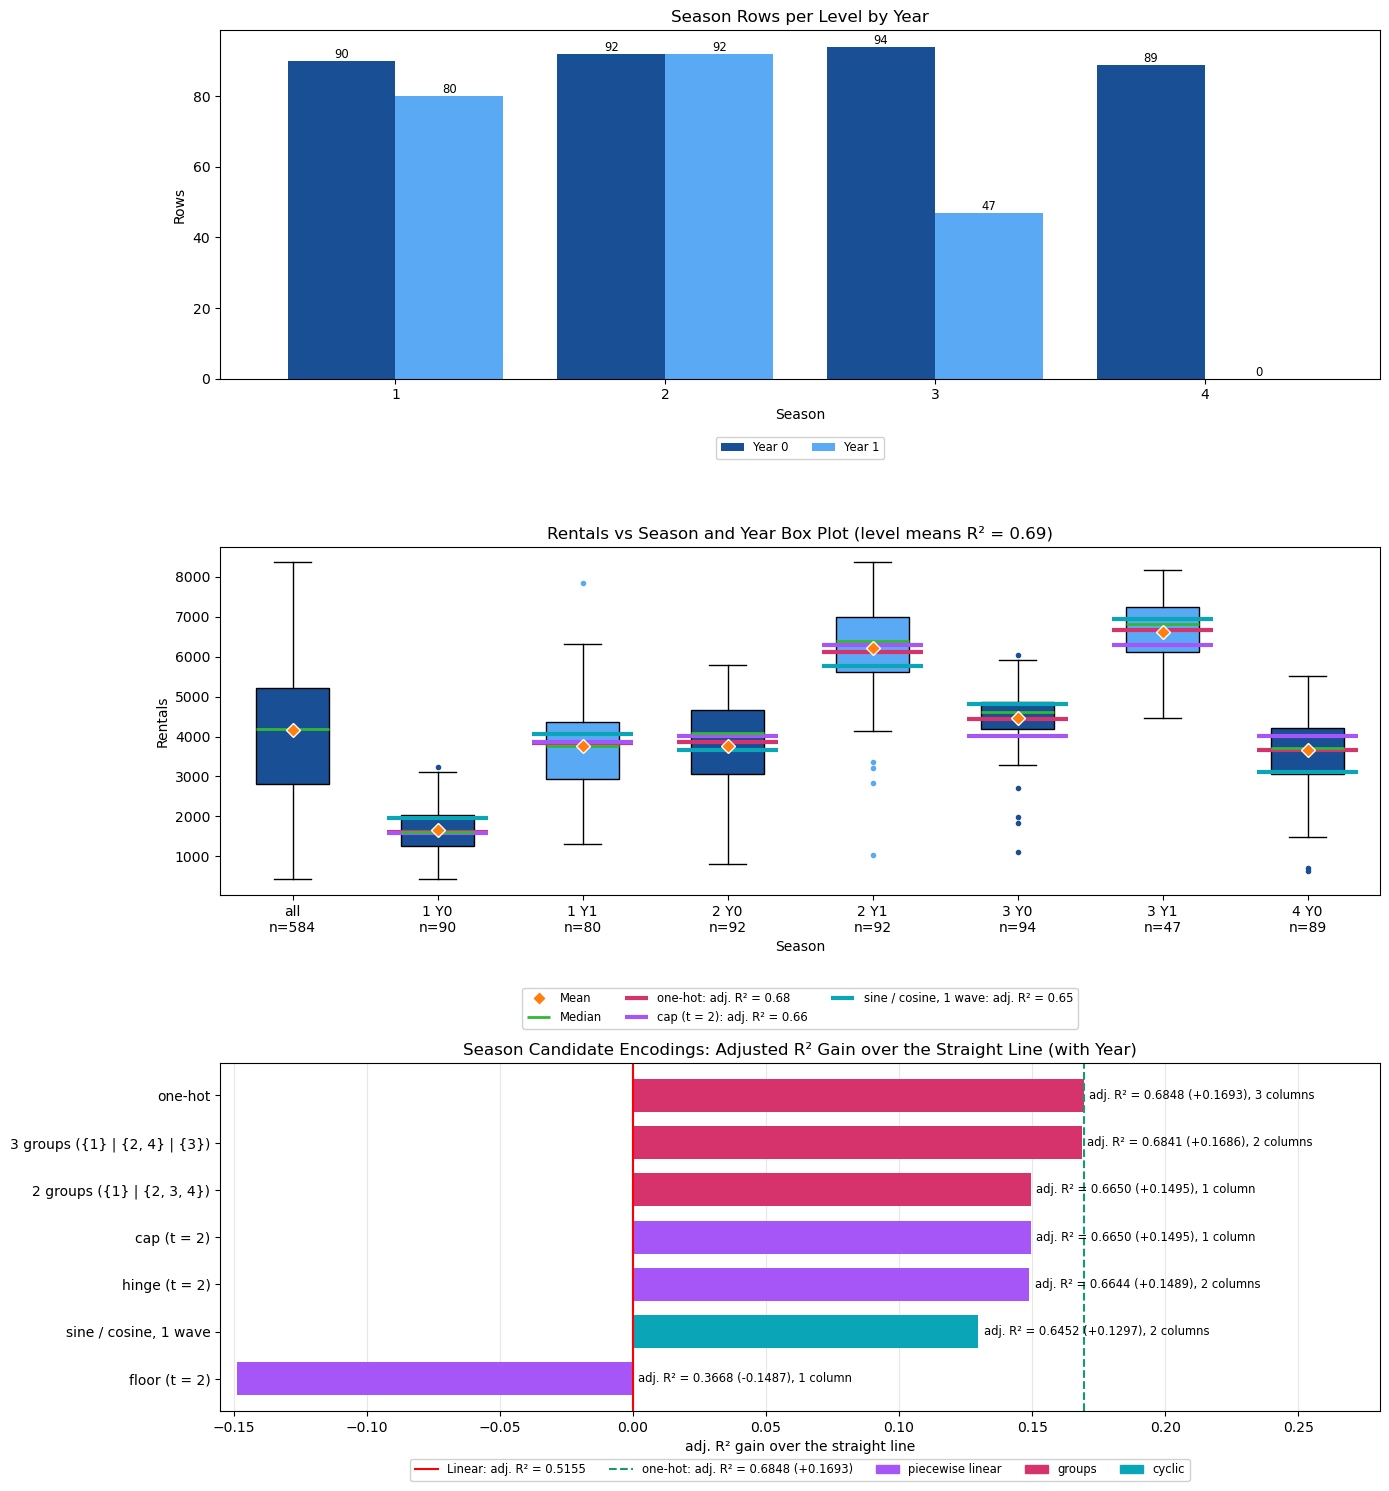

In [20]:
PLOTTING.categorical_single_feature_plots(df=train_df, feature='Season', by='Year', target=Q2_CONSTS.TARGET, period=4);

### Interactions with Continuous Attributes

This table crosses `Season` with each continuous attribute on purpose, to check whether `Season` changes how that attribute moves `Rentals`.

In [21]:
STATISTICS.interaction_r2_df(df=train_df, feature='Season', target=Q2_CONSTS.TARGET, continuous=Q2_CONSTS.CONTINUOUS)

,adjusted r2 without,adjusted r2 with,gain,columns added
continuous attribute,,,,
Temp,0.5109,0.5207,0.0098,3
FeelsLike,0.5137,0.5229,0.0092,3
Humidity,0.3982,0.4142,0.0161,3
Wind,0.3810,0.3819,0.0009,3


### Notes / Observations

#### Noticeable Traits / Key Attributes

- No second-year season 4: `Season` 4 has no `Year` 1 rows, and most of the test dates (2012-08-07 to 2012-12-31) fall in that stretch of the calendar. With one-hot, a season 4 test day would be predicted from first-year season 4 days plus the `Year` 1 shift.
- Season 4 looks low only without `Year`: it holds first-year days alone, and within `Year` 0 it is about level with season 2 (3,664 against 3,775). That is why the plain chart groups season 2 with 3, and the (with Year) chart groups it with 4.
- Much of the plain chart's gain was really `Year`: the best gain falls from +0.28 to +0.17 once `Year` is in the fit.

#### Special Treatment

- **Feature engineering:** recommend 3 groups ({1} | {2, 4} | {3}, +0.17): two 0 / 1 columns, "season 2 or 4" and "season 3", with season 1 as the baseline. With `Year` in the fit it ties one-hot with one column fewer, and season 4 shares its coefficient with season 2, which has both years. Avoid 2 groups ({1} | {2, 3, 4}, the same fit as the cap at t = 2): it is in the recommend tier but more than 0.01 behind the best (+0.15), and it gives season 3 days the lower prediction of seasons 2 and 4.
- **Encoding:** if the groups are not used, one-hot (one 0 / 1 column per level, with one level left out as the baseline, so 3 columns for 4 levels). Avoid the code as a number, and sine / cosine with 1 wave: more than 0.01 behind the groups, with as many columns.
- **Interactions:** `Season` by `Humidity` is worth testing, small gain (+0.02, one `Humidity` slope per season). Avoid it with `Temp`, `FeelsLike` and `Wind`, which gain less, and avoid `Year` by `Season`: season 4 has no `Year` 1 rows to fit it.

## Month (with Year Context)

In [22]:
STATISTICS.categorical_statistics_df(df=train_df, feature='Month', target=Q2_CONSTS.TARGET)

,count,% of rows,mean,std,min,25%,50%,75%,max,mean - overall mean
Month,,,,,,,,,,
1,62,10.616,2176.339,1161.674,431.0,1251.75,1939.0,3235.75,4521.0,-1977.261
2,57,9.760,2655.298,1145.313,1005.0,1623.00,2402.0,3777.00,5062.0,-1498.301
3,62,10.616,3692.258,1899.302,605.0,2077.00,3216.5,5361.00,8362.0,-461.341
4,60,10.274,4484.900,1776.161,795.0,3188.25,4293.5,6205.25,7460.0,331.301
5,62,10.616,5349.774,1298.712,2633.0,4409.00,4890.5,6405.50,8294.0,1196.175
6,60,10.274,5772.367,1240.400,3767.0,4834.50,5308.5,6983.00,8120.0,1618.767
7,62,10.616,5563.677,1273.752,3285.0,4491.50,5446.5,6678.75,8173.0,1410.078
8,37,6.336,4811.027,1216.343,1115.0,4266.00,4694.0,5130.00,7580.0,657.428
9,30,5.137,4247.267,965.377,1842.0,3721.00,4584.5,4828.00,5423.0,93.667


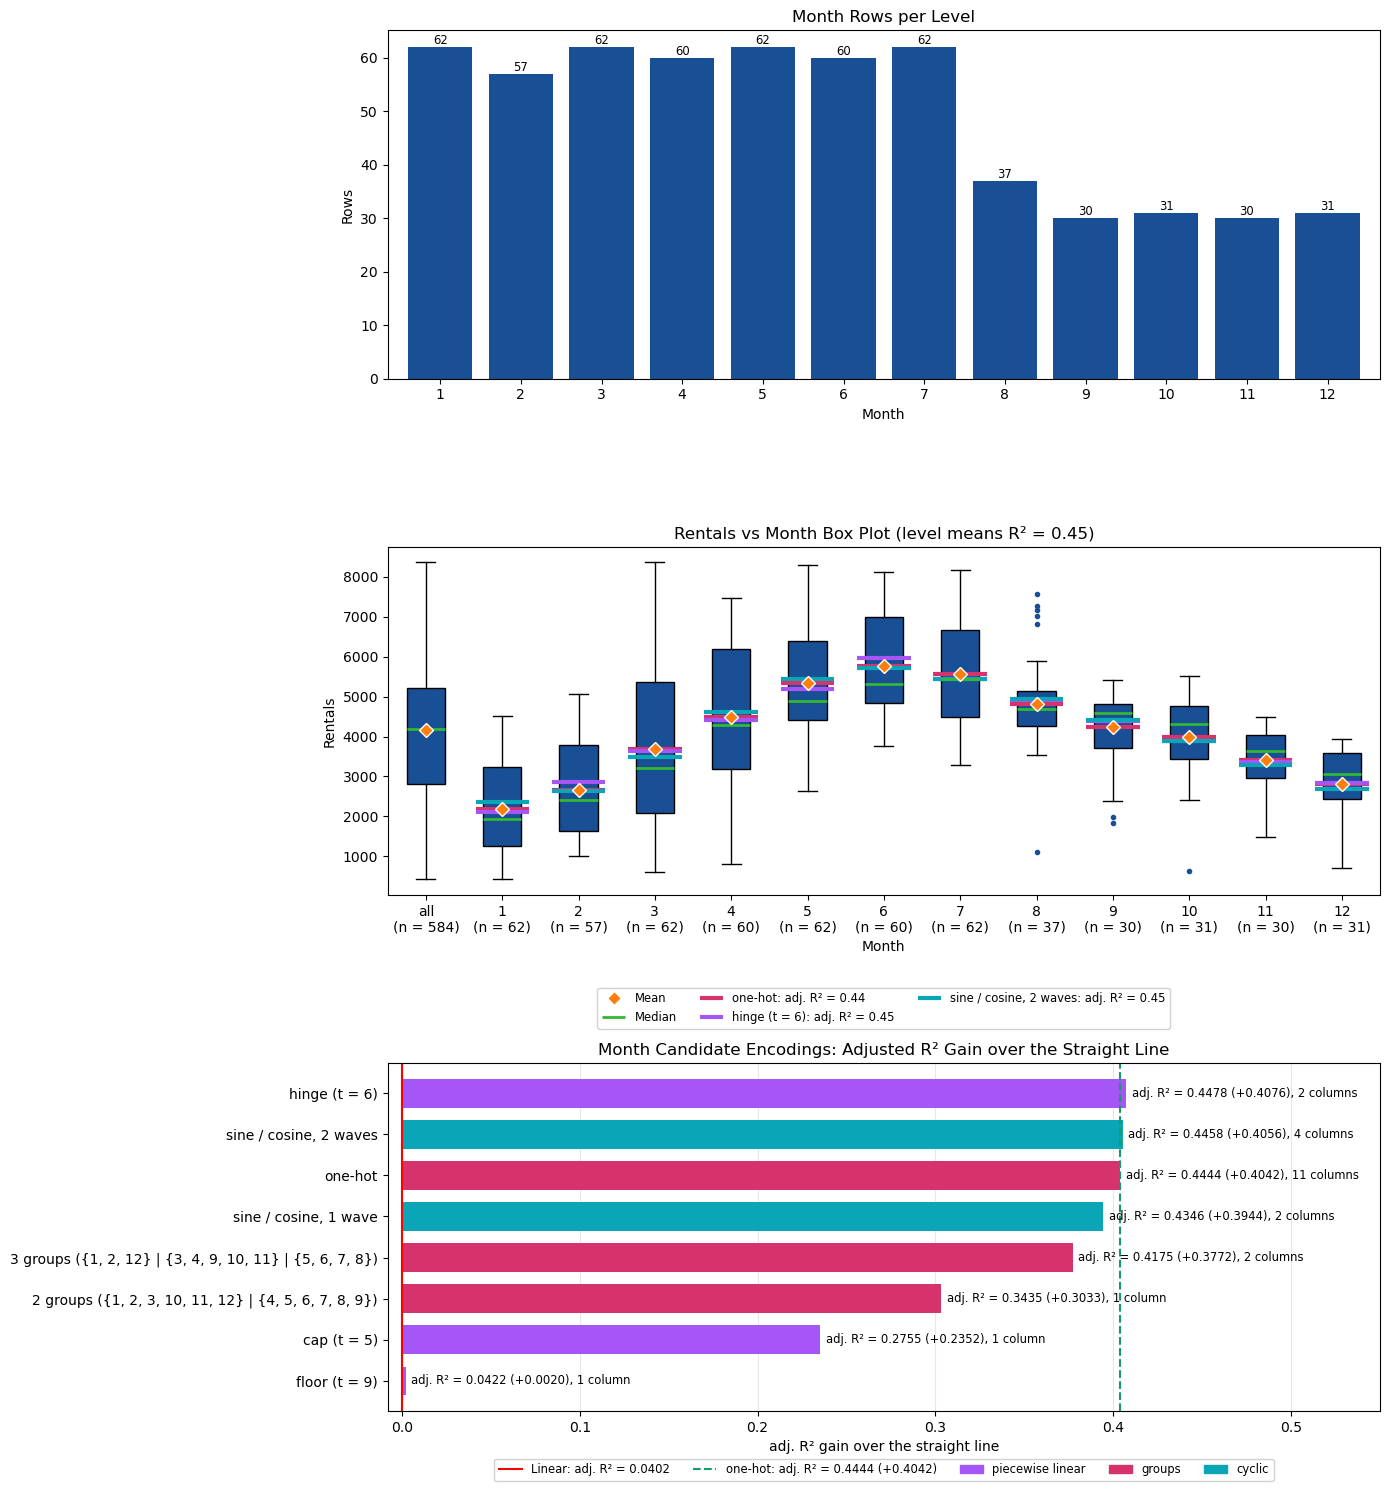

In [23]:
PLOTTING.categorical_single_feature_plots(df=train_df, feature='Month', target=Q2_CONSTS.TARGET, period=12);

### Year Context

The chronological split leaves months 9 to 12 with `Year` 0 rows only in train (the rows per level chart below shows 0 `Year` 1 rows for them), and most of the test days (2012-08-07 to 2012-12-31, the split table) fall in that stretch of the calendar. So the single attribute view above mixes the two years: months 1 to 8 hold days from both years, months 9 to 12 first-year days alone. That is why this section crosses `Month` with `Year`, a stated exception to looking at one attribute at a time. The table and plots below split every month by `Year`.

In [24]:
STATISTICS.categorical_statistics_df(df=train_df, feature='Month', by='Year', target=Q2_CONSTS.TARGET)

count  % of rows      mean       std     min      25%     50%  \
Month Year                                                                  
1     0        31      5.308  1231.903   372.433   431.0   985.50  1248.0   
      1        31      5.308  3120.774   872.852  1301.0  2339.50  3243.0   
2     0        28      4.795  1721.964   398.509  1005.0  1512.50  1629.0   
      1        29      4.966  3556.448   870.725  1529.0  2947.00  3777.0   
3     0        31      5.308  2065.968   550.972   605.0  1868.50  2077.0   
      1        31      5.308  5318.548  1251.163  3194.0  4473.50  5382.0   
4     0        30      5.137  3162.333  1042.094   795.0  2302.75  3226.5   
      1        30      5.137  5807.467  1308.939  1027.0  5449.75  6214.5   
5     0        31      5.308  4381.323   572.928  2633.0  4114.00  4451.0   
      1        31      5.308  6318.226  1078.404  2843.0  5893.00  6421.0   
6     0        30      5.137  4783.733   444.448  3767.0  4557.50  4839.5   
      1        30      5.137  6761.000   954.205  4127.0  6307.75  6988.0   
7     0        31      5.308  4559.387   680.091  3285.0  4172.00  4541.0   
      1        31      5.308  6567.968   867.184  4459.0  6217.00  6685.0   
8     0        31      5.308  4409.387   809.852  1115.0  4151.50  4602.0   
      1         6      1.027  6886.167   741.328  5464.0  6871.25  7094.0   
9     0        30      5.137  4247.267   965.377  1842.0  3721.00  4584.5   
10    0        31      5.308  3984.226  1103.482   627.0  3450.50  4304.0   
11    0        30      5.137  3405.567   788.249  1495.0  2963.00  3631.0   
12    0        31      5.308  2816.871   958.763   705.0  2427.00  3068.0   

                75%     max  mean - overall mean  
Month Year                                        
1     0     1505.50  1985.0            -2921.696  
      1     3823.50  4521.0            -1032.825  
2     0     1839.50  2927.0            -2431.635  
      1     4169.00  5062.0             -597.151  
3     0     2313.50  3239.0            -2087.632  
      1     6143.00  8362.0             1164.949  
4     0     4013.00  5312.0             -991.266  
      1     6538.75  7460.0             1653.867  
5     0     4696.50  5805.0              227.723  
      1     6956.50  8294.0             2164.626  
6     0     5094.25  5515.0              630.134  
      1     7454.00  8120.0             2607.401  
7     0     4982.50  6043.0              405.788  
      1     7160.50  8173.0             2414.368  
8     0     4818.50  5895.0              255.788  
      1     7239.50  7580.0             2732.567  
9     0     4828.00  5423.0               93.667  
10    0     4756.50  5511.0             -169.374  
11    0     4043.25  4486.0             -748.033  
12    0     3595.50  3940.0            -1336.728

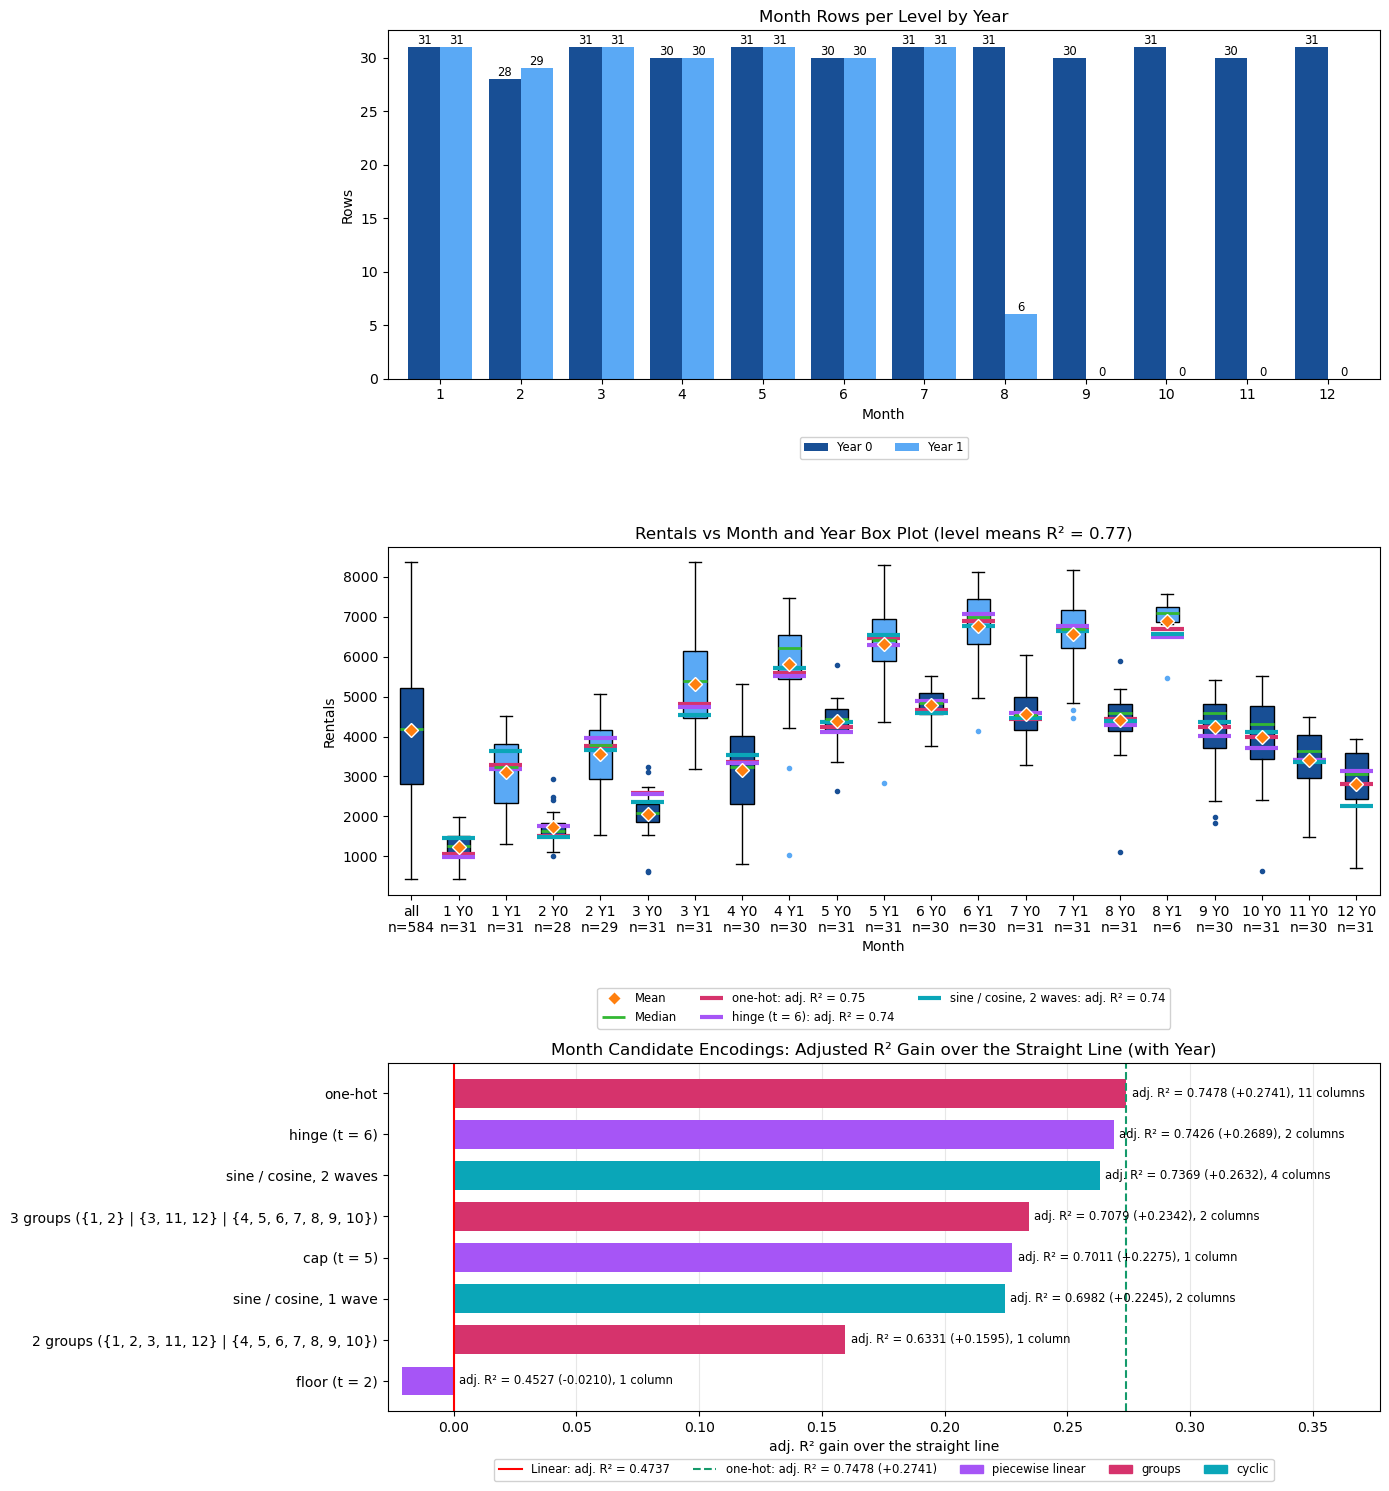

In [25]:
PLOTTING.categorical_single_feature_plots(df=train_df, feature='Month', by='Year', target=Q2_CONSTS.TARGET, period=12);

### Interactions with Continuous Attributes

This table crosses `Month` with each continuous attribute on purpose, to check whether `Month` changes how that attribute moves `Rentals`.

In [26]:
STATISTICS.interaction_r2_df(df=train_df, feature='Month', target=Q2_CONSTS.TARGET, continuous=Q2_CONSTS.CONTINUOUS)

,adjusted r2 without,adjusted r2 with,gain,columns added
continuous attribute,,,,
Temp,0.5108,0.5677,0.0570,11
FeelsLike,0.5140,0.5758,0.0618,11
Humidity,0.4759,0.5176,0.0417,11
Wind,0.4593,0.4628,0.0035,11


### Notes / Observations

#### Noticeable Traits / Key Attributes

- Most test months are first-year only: months 9 to 12 have no `Year` 1 rows and month 8 has 6, and most of the test dates fall in that stretch. With one-hot, month 12 would be predicted from its first-year days alone plus the `Year` 1 shift.
- Up, then down: with `Year` in the fit, two straight runs carry the whole month effect, up to month 6 and down after it. The hinge at month 6 matches one-hot with two columns instead of eleven (+0.27 each).
- Much of the plain chart's gain was really `Year`: the best gain falls from +0.41 to +0.27 once `Year` is in the fit.
- The `Year` gap is not the same every month: it differs by month (largest at month 3), so the single `Year` 1 shift added to the test months is an average of the gaps in months 1 to 8.

#### Special Treatment

- **Feature engineering:** recommend the hinge at month 6 (`Month` as a number plus `max(0, Month - 6)`, +0.27: one slope up to month 6, another after it). Months 9 to 12 are then predicted from one falling line that months 7 and 8 (which have `Year` 1 rows) also set, instead of from separate first-year means. Avoid the groups, the cap and the floor: the best of them, 3 groups, is in the recommend tier but more than 0.01 behind the hinge (+0.23).
- **Encoding:** prefer the hinge over one-hot (one 0 / 1 column per month, with one month left out as the baseline, so 11 columns for 12 months) and over sine / cosine with 2 waves: all three tie with `Year` in the fit, and the hinge has the fewest columns. Avoid sine / cosine with 1 wave, more than 0.01 behind the best, and the code as a number.
- **Interactions:** recommend `Month` by `FeelsLike`, `Temp` or `Humidity`, one slope per month (+0.04 to +0.06). These gains were measured with one-hot `Month` and without `Year`, and the slopes for months 9 to 12 would be learned from first-year days only. Avoid it with `Wind`, which gains nothing, and avoid `Year` by `Month`: months 9 to 12 have no `Year` 1 rows to fit it.

## Weekday

In [27]:
STATISTICS.categorical_statistics_df(df=train_df, feature='Weekday', target=Q2_CONSTS.TARGET)

,count,% of rows,mean,std,min,25%,50%,75%,max,mean - overall mean
Weekday,,,,,,,,,,
0,84,14.384,3997.417,1795.027,605.0,2729.5,4032.0,5076.75,7641.0,-156.183
1,84,14.384,4051.738,1627.219,1000.0,3125.5,4092.0,5039.75,7105.0,-101.861
2,83,14.212,4211.892,1676.713,683.0,2924.5,4451.0,5108.50,7592.0,58.292
3,83,14.212,4085.711,1843.334,506.0,2392.0,4186.0,5094.00,8173.0,-67.888
4,83,14.212,4271.048,1794.236,431.0,3060.5,4189.0,5395.50,7494.0,117.449
5,83,14.212,4290.012,1747.653,1167.0,3204.0,4151.0,5337.00,8362.0,136.413
6,84,14.384,4170.286,2049.309,627.0,2491.0,4257.0,5361.00,8294.0,16.686


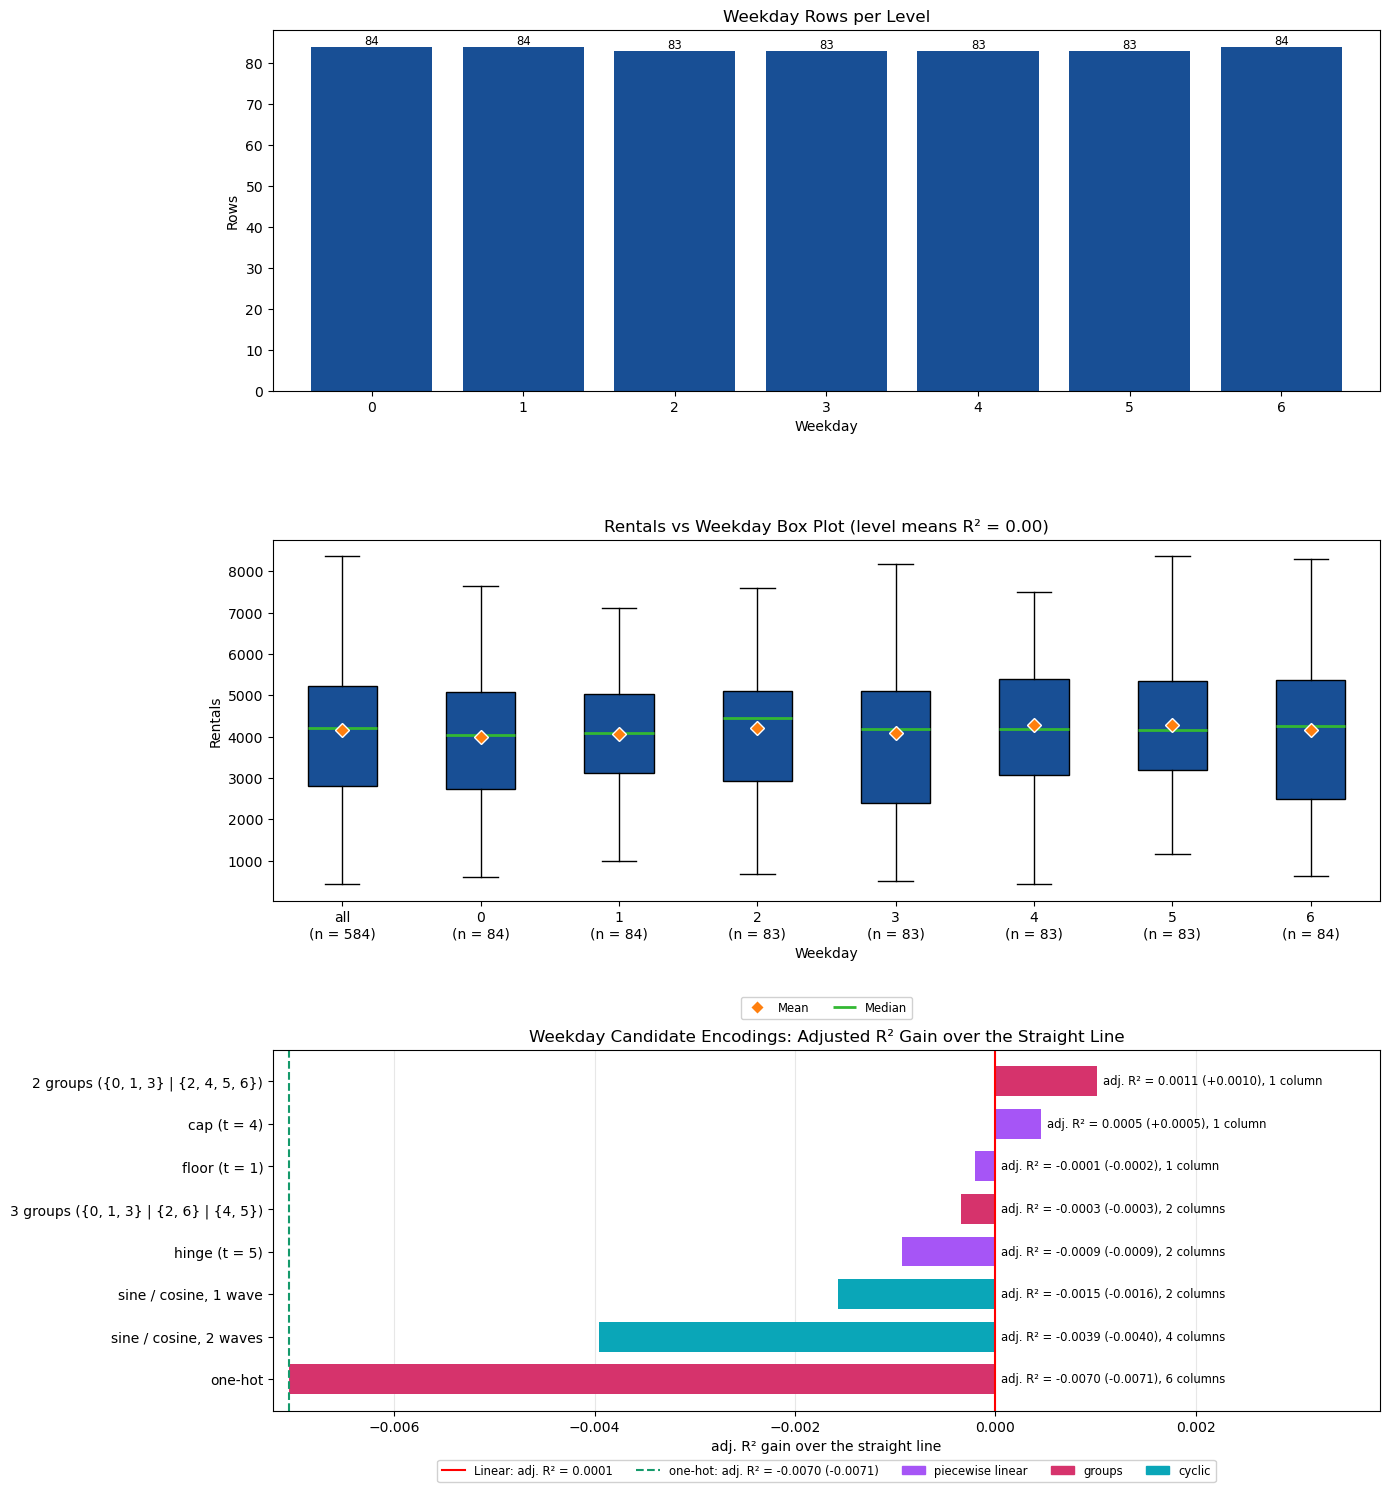

In [28]:
PLOTTING.categorical_single_feature_plots(df=train_df, feature='Weekday', target=Q2_CONSTS.TARGET, period=7);

### Interactions with Continuous Attributes

This table crosses `Weekday` with each continuous attribute on purpose, to check whether `Weekday` changes how that attribute moves `Rentals`.

In [29]:
STATISTICS.interaction_r2_df(df=train_df, feature='Weekday', target=Q2_CONSTS.TARGET, continuous=Q2_CONSTS.CONTINUOUS)

,adjusted r2 without,adjusted r2 with,gain,columns added
continuous attribute,,,,
Temp,0.4661,0.4622,-0.0039,6
FeelsLike,0.4725,0.4686,-0.0039,6
Humidity,0.0071,0.0152,0.0081,6
Wind,0.0306,0.0387,0.0082,6


### Notes / Observations

#### Noticeable Traits / Key Attributes

- No signal: `Rentals` do not change with `Weekday` (level means R² 0.00), and the levels are evenly filled, so this is not a matter of thin levels.
- One-hot loses ground: its gain is -0.01 once adjusted R² subtracts the cost of its 6 columns, so weekday coefficients would move predictions by noise.

#### Special Treatment

- **Dropping:** recommend dropping it: no candidate gains more than +0.00 over the straight line, which itself explains nothing.
- **Interactions:** avoid `Weekday` by any continuous attribute (largest gain +0.01, `Wind`).

## IsWorkday

In [30]:
STATISTICS.categorical_statistics_df(df=train_df, feature='IsWorkday', target=Q2_CONSTS.TARGET)

,count,% of rows,mean,std,min,25%,50%,75%,max,mean - overall mean
IsWorkday,,,,,,,,,,
0,184,31.507,4039.690,1935.064,605.0,2481.5,4108.0,5318.0,8294.0,-113.909
1,400,68.493,4205.998,1717.480,431.0,2983.0,4268.0,5142.5,8362.0,52.398


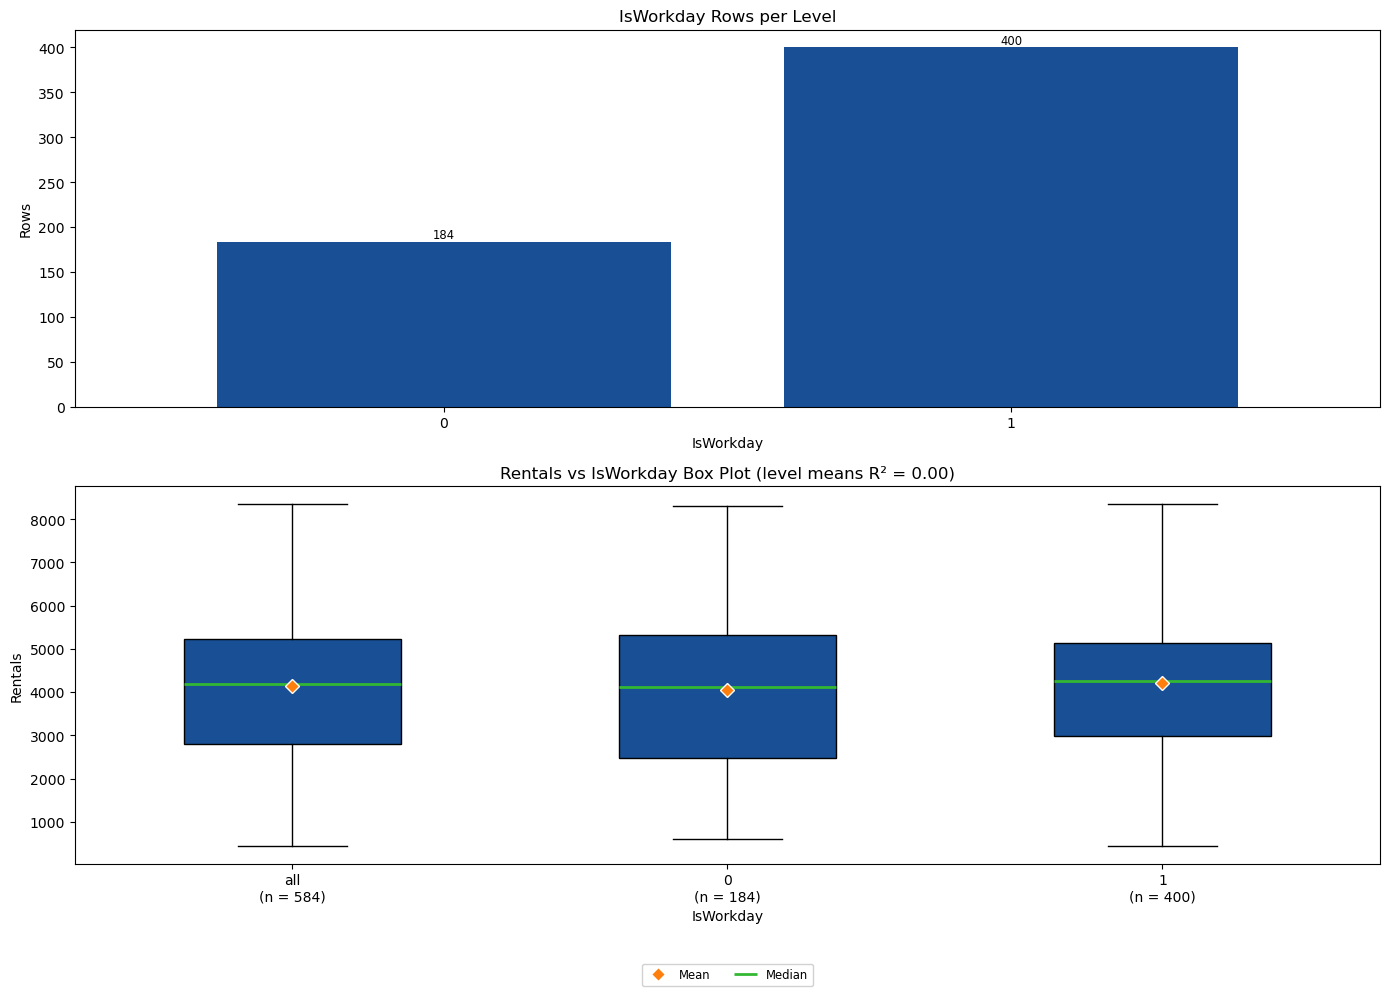

In [31]:
PLOTTING.categorical_single_feature_plots(df=train_df, feature='IsWorkday', target=Q2_CONSTS.TARGET);

### Interactions with Continuous Attributes

This table crosses `IsWorkday` with each continuous attribute on purpose, to check whether `IsWorkday` changes how that attribute moves `Rentals`.

In [32]:
STATISTICS.interaction_r2_df(df=train_df, feature='IsWorkday', target=Q2_CONSTS.TARGET, continuous=Q2_CONSTS.CONTINUOUS)

,adjusted r2 without,adjusted r2 with,gain,columns added
continuous attribute,,,,
Temp,0.4674,0.4681,0.0007,1
FeelsLike,0.4738,0.4742,0.0004,1
Humidity,0.0151,0.0167,0.0016,1
Wind,0.0371,0.0505,0.0134,1


### Notes / Observations

#### Noticeable Traits / Key Attributes

- No signal: workdays and other days rent about the same (level means R² 0.00), and both levels are well filled, so the 0 / 1 column would get a coefficient near 0 from plenty of days.

#### Special Treatment

- **Dropping:** recommend dropping it: the two level means are close (4,040 against 4,206).
- **Interactions:** avoid `IsWorkday` by any continuous attribute (largest gain +0.01, `Wind`).

## IsHoliday

In [33]:
STATISTICS.categorical_statistics_df(df=train_df, feature='IsHoliday', target=Q2_CONSTS.TARGET)

,count,% of rows,mean,std,min,25%,50%,75%,max,mean - overall mean
IsHoliday,,,,,,,,,,
0,568,97.26,4169.87,1779.748,431.0,2840.25,4262.0,5219.0,8362.0,16.270
1,16,2.74,3576.00,2068.932,1000.0,1837.00,3240.0,5348.5,7403.0,-577.599


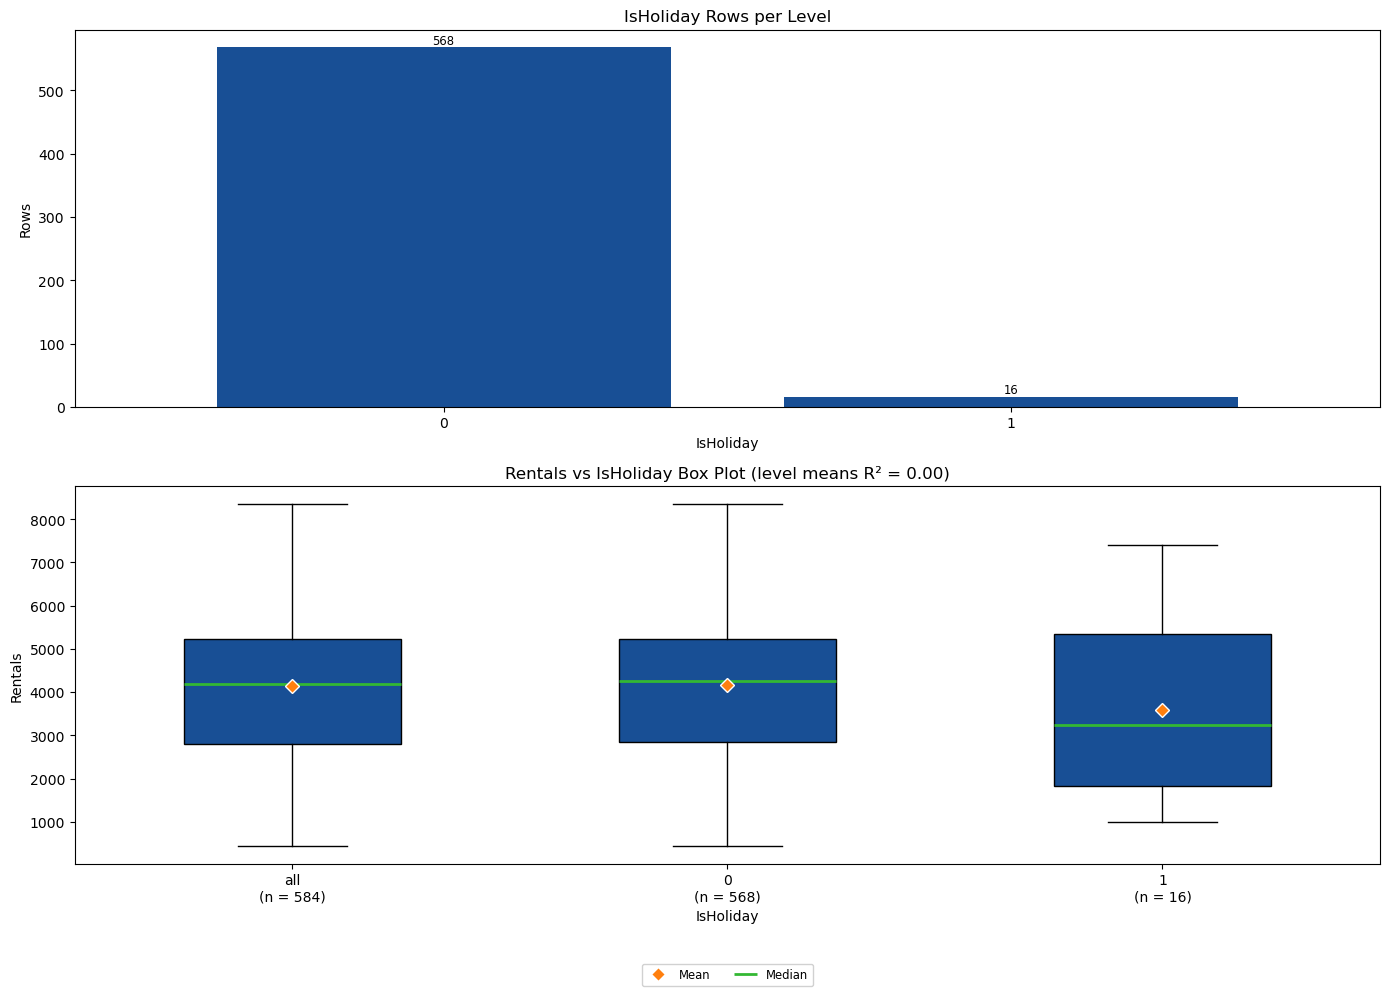

In [34]:
PLOTTING.categorical_single_feature_plots(df=train_df, feature='IsHoliday', target=Q2_CONSTS.TARGET);

### Interactions with Continuous Attributes

This table crosses `IsHoliday` with each continuous attribute on purpose, to check whether `IsHoliday` changes how that attribute moves `Rentals`.

In [35]:
STATISTICS.interaction_r2_df(df=train_df, feature='IsHoliday', target=Q2_CONSTS.TARGET, continuous=Q2_CONSTS.CONTINUOUS)

,adjusted r2 without,adjusted r2 with,gain,columns added
continuous attribute,,,,
Temp,0.4688,0.4690,0.0002,1
FeelsLike,0.4749,0.4749,-0.0000,1
Humidity,0.0165,0.0207,0.0043,1
Wind,0.0376,0.0387,0.0011,1


### Notes / Observations

#### Noticeable Traits / Key Attributes

- Rare level: only 16 rows at level 1, so its coefficient would rest on 16 days.
- No signal: those days average fewer rentals but spread widely (the widest box on the chart), so the column explains nothing (level means R² 0.00) and would move every holiday's prediction by an unreliable amount.

#### Special Treatment

- **Dropping:** recommend dropping it: level means R² 0.00.
- **Interactions:** avoid `IsHoliday` by any continuous attribute: every gain is +0.00, and each holiday slope would rest on few days.

## Weather

In [36]:
STATISTICS.categorical_statistics_df(df=train_df, feature='Weather', target=Q2_CONSTS.TARGET)

,count,% of rows,mean,std,min,25%,50%,75%,max,mean - overall mean
Weather,,,,,,,,,,
1,377,64.555,4509.897,1742.077,431.0,3387.0,4586.0,5687.0,8294.0,356.297
2,189,32.363,3665.101,1656.598,605.0,2368.0,3747.0,4576.0,8362.0,-488.499
3,18,3.082,1820.389,1020.114,506.0,853.0,1829.5,2422.0,4459.0,-2333.210


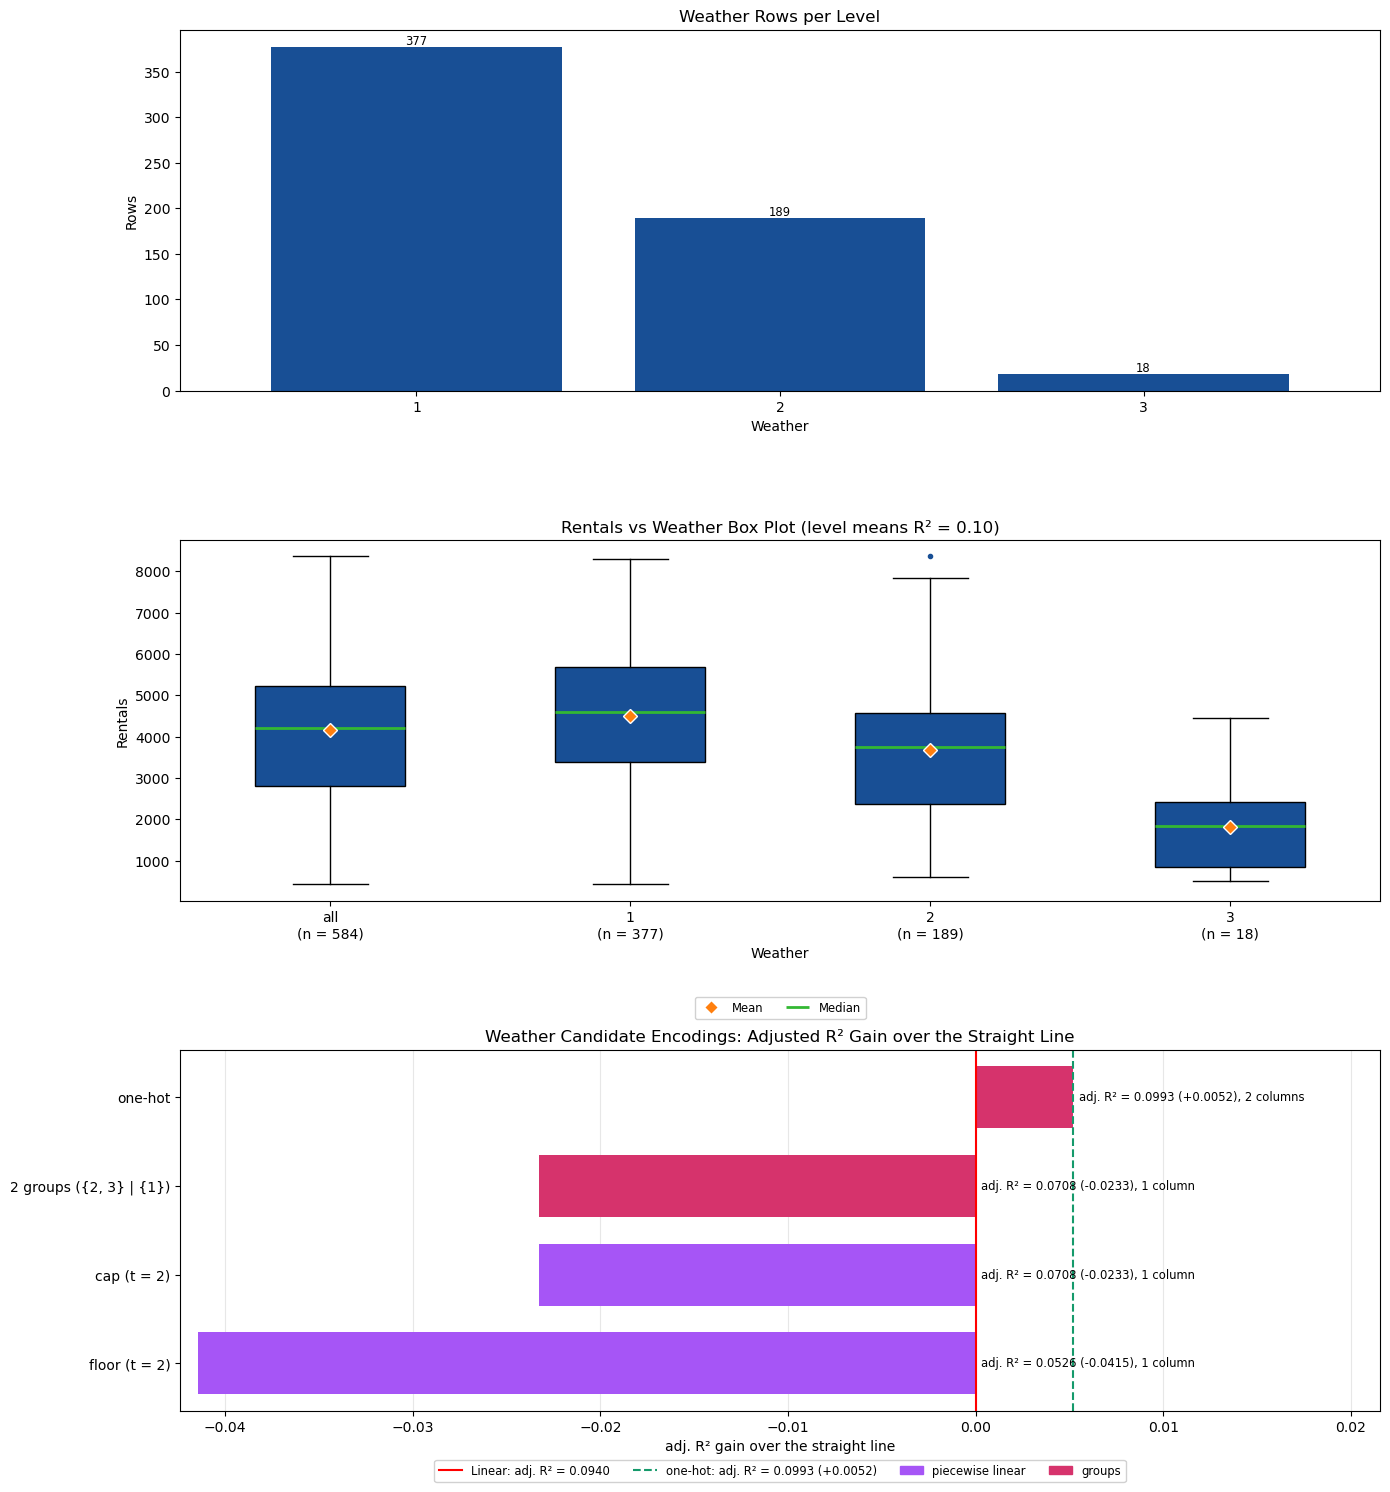

In [37]:
PLOTTING.categorical_single_feature_plots(df=train_df, feature='Weather', target=Q2_CONSTS.TARGET);

### Interactions with Continuous Attributes

This table crosses `Weather` with each continuous attribute on purpose, to check whether `Weather` changes how that attribute moves `Rentals`.

In [38]:
STATISTICS.interaction_r2_df(df=train_df, feature='Weather', target=Q2_CONSTS.TARGET, continuous=Q2_CONSTS.CONTINUOUS)

,adjusted r2 without,adjusted r2 with,gain,columns added
continuous attribute,,,,
Temp,0.5252,0.5250,-0.0002,2
FeelsLike,0.5303,0.5304,0.0002,2
Humidity,0.1016,0.1030,0.0014,2
Wind,0.1302,0.1317,0.0014,2


### Notes / Observations

#### Noticeable Traits / Key Attributes

- Falling, with a larger last drop: the means fall in code order, but the drop to level 3 is the larger one, so one slope on the code predicts level 3 days too high.
- The misfit is on few days: level 3 is rare (18 rows), so fixing those days with one-hot gains little over the straight line.

#### Special Treatment

- **Encoding:** recommend the code as a number (the straight line): one-hot (one 0 / 1 column per level, with one level left out as the baseline, so 2 columns for 3 levels) falls in the avoid tier over it.
- **Feature engineering:** avoid every merge, each loses adjusted R² (-0.02 and -0.04): 2 groups ({2, 3} | {1}, the same fit as the cap) gives level 3 days the prediction of level 2, and the floor gives level 1 days the prediction of level 2.
- **Interactions:** avoid `Weather` by any continuous attribute (+0.00 for each).